# Slab pile cooling in an open yard

Transient cooling of a stacked slab pile: the jagged slab to slab contact, the open yard soil
under the bottom slab, the overhang wings, the gradients inside a slab, and a Monte Carlo
release envelope. The last cells report how long each slab takes to reach the release
temperature, which is the number the yard actually schedules against.


## Problem and physical model

Hot rolled or continuously cast slabs stacked in a storage yard cool through a combination of
effects.

Conduction inside each slab. The transient problem is

$$\rho\,c_p^{\text{eff}}(T)\,\frac{\partial T}{\partial t} = \nabla \cdot \big(k(T)\,\nabla T\big)$$

with $k(T)$ and $c_p^{\text{eff}}(T)$ from Eurocode 3 (EN 1993-1-2). The apparent specific heat
carries the transformation latent heat, about 85 kJ/kg, centred at 735 °C.

The ground under the pile. Slabs in an open yard rest on compacted earth, gravel or dunnage
sleepers, so the soil is not an infinite sink. It is a conduction layer
($k_{\text{soil}} \approx 1.2$ to $1.6$ W/m·K, $\rho c_p \approx 1.8$ MJ/m³K) that warms up
beneath the pile and reduces bottom heat loss as it does.

Contact between slabs. The interface conductance is the sum of three paths,

$$h_c = h_s + h_g + h_r$$

- $h_s = 1.25\,k_s\,\frac{m}{\sigma}\,\left(\frac{P}{H(T)}\right)^{0.95}$ is the asperity
  contact path (Cooper, Mikic and Yovanovich), where $H(T)$ is the hot hardness, $\sigma$ the rms
  roughness, $m$ the mean asperity slope and $P$ the contact pressure.
- $h_g = \frac{k_{\text{air}}(T)}{Y + Y_{\text{wav}}}$ is the gas path, over the roughness
  separation $Y$ and the waviness or camber gap, 0.2 to 1.0 mm.
- $h_r = \frac{\sigma_{SB}\,(T_1^2 + T_2^2)(T_1 + T_2)}{1/\varepsilon_1 + 1/\varepsilon_2 - 1}$
  is the radiation across the gap.
- Hot air leaving the open gap edges lifts the gas path within about 80 mm of the perimeter.

Overhang. A slab that is wider or longer than the one below leaves bare wings. Those wings
cool from above and below at the same time, which is where the fastest surface cooling in a
mixed pile happens.

Gradients and thermal stress. The through-thickness difference
$\Delta T = T_{\text{core}} - T_{\text{surface}}$ and the lateral wing to root gradient put the
surface into tension:

$$\sigma_{\text{surf}} \approx \frac{E(T)\,\alpha(T)}{1 - \nu}\,\frac{2}{3}\,\Delta T$$

The ratio of that stress to the temperature-dependent yield strength $R_{eH}(T)$ is the index the
notebook reports as cracking risk.

Uncertainty. Wind, gap waviness, scale thickness, soil conductivity and ambient temperature
are not known to the planner at the moment the decision is made, so the pile is run over
plausible ranges and reported as a P10, P50 and P90 envelope rather than one number.


## The simulation engine, carried inside this notebook

Everything the run needs is defined below, in this notebook: the data model, the property
functions, the contact model, the mesh, the finite volume solver, the analytical checks, the
uncertainty engine and the figures. About 2,500 lines, split over eight cells so it stays
navigable.

It runs with no file beside it. In a folder holding nothing but this notebook it reaches 805
time steps on the width section at 0.92 per cent energy imbalance, 593 on the length section at
0.15 per cent, 118.2 hours to clear the pile, and P10, P50, P90 of 103.5, 114.5 and 126.3 hours.


Engine part 1 of 8, the configuration and the data model. Defines `Slab`, `ContactParams`, `SoilParams`, `EnvironmentParams`, `SimulationConfig`.


In [1]:
"""
Slab piling heat transfer engine 
=============================================================================
Transient cooling of stacked hot steel slabs
with imperfect thermal contact, hangover (overhang) effects, temperature-dependent
properties, phase transformation latent heat, open yard transient soil foundation,
diurnal weather cycles, thermal gradient & stress tracking, and Monte Carlo UQ.

Finite volume method with a sparse matrix solve at each step
transient cooling analysis, interactive notebooks, and operational planning.
"""

from dataclasses import dataclass, field
from typing import List, Dict, Tuple, Optional, Union
import numpy as np
import scipy.sparse as sp
import scipy.sparse.linalg as spla
import pandas as pd


# 1. configuration and data structures

@dataclass
class Slab:
    """Individual steel slab definition with optional stacking offsets."""
    id: int
    thickness: float     # mm
    width: float         # mm
    length: float        # mm
    initial_temp: float  # °C
    label: str = ""
    offset_x: float = 0.0  # mm, lateral offset from centerline (width direction)
    offset_y: float = 0.0  # mm, longitudinal offset from centerline (length direction)

    def __post_init__(self):
        if not self.label:
            self.label = f"Slab {self.id}"

    @property
    def thickness_m(self) -> float:
        return self.thickness / 1000.0

    @property
    def width_m(self) -> float:
        return self.width / 1000.0

    @property
    def length_m(self) -> float:
        return self.length / 1000.0

    @property
    def offset_x_m(self) -> float:
        return self.offset_x / 1000.0

    @property
    def offset_y_m(self) -> float:
        return self.offset_y / 1000.0

    @property
    def volume_m3(self) -> float:
        return self.thickness_m * self.width_m * self.length_m

    @property
    def mass_kg(self) -> float:
        # Reference density 7850 kg/m³
        return 7850.0 * self.volume_m3


@dataclass
class ContactParams:
    """Interface contact parameters based on Yovanovich / CMY contact mechanics."""
    roughness_sigma: float = 30.0e-6    # Combined RMS roughness (m), typ 20-50 um
    roughness_slope: float = 0.1        # Combined mean absolute asperity slope (dimensionless)
    emissivity: float = 0.82            # Surface emissivity (oxidized steel mill scale)
    gap_waviness: float = 0.4e-3        # Macro air gap from waviness/camber between slabs (m), typ 0.2-1.0 mm
    scale_thickness: float = 25.0e-6    # Mill scale layer thickness per face (m)
    scale_conductivity: float = 2.5     # Oxide scale thermal conductivity (W/m·K)
    h_c_scale: float = 1.0              # Empirical tuning multiplier (0.5 - 2.0)
    edge_draft_factor: float = 1.25     # Buoyancy draft enhancement at open gap edges
    flatness_factor: float = 1.0        # Macro contact fraction factor (default 1.0 for standard CMY)


@dataclass
class SoilParams:
    """Open yard soil ground foundation parameters."""
    enabled: bool = True                # True: transient multi-layer soil floor; False: fixed h_ground
    conductivity: float = 1.4           # Soil thermal conductivity (W/m·K), typ 1.0-1.8
    density: float = 1800.0             # Soil density (kg/m³), typ 1600-2000
    specific_heat: float = 1000.0       # Soil specific heat (J/kg·K), typ 800-1200
    depth: float = 1.5                  # Modeled soil depth beneath pile (m)
    deep_temp: float = 25.0             # Deep ground temperature at bottom boundary (°C)
    contact_conductance: float = 80.0   # Slab-to-soil contact conductance (W/m²·K)
    width_extension: float = 0.5        # Soil lateral overhang beyond base slab edge (m)


@dataclass
class EnvironmentParams:
    """Ambient environment and weather parameters for open yard storage."""
    t_ambient: float = 30.0             # Mean ambient air temperature (°C)
    t_sky: float = 25.0                 # Effective clear sky temperature (°C)
    wind_speed: float = 0.8             # Wind velocity (m/s)
    h_ground: float = 8.0               # Fallback boundary conductance if soil is disabled (W/m²·K)
    f_cavity: float = 0.7               # Radiation/convection shielding for overhang undersides
    h_override: Optional[float] = None  # Impose constant convective h on all faces (verification only)
    t_diurnal_amp: float = 0.0          # Diurnal ambient temperature swing amplitude (°C, 0=off)
    solar_flux_max: float = 0.0         # Peak daytime solar radiation (W/m², 0=off)
    rain_enabled: bool = False          # Simulate sudden rain quench event
    rain_start_h: float = 12.0          # Rain start time (hours)
    rain_duration_h: float = 2.0        # Rain duration (hours)
    rain_h_extra: float = 250.0         # Convective/evaporative quench h during rain (W/m²·K)


@dataclass
class SimulationConfig:
    """Master simulation configuration."""
    slabs: List[Slab] = field(default_factory=list)
    contact: ContactParams = field(default_factory=ContactParams)
    env: EnvironmentParams = field(default_factory=EnvironmentParams)
    soil: SoilParams = field(default_factory=SoilParams)
    t_rtp: float = 50.0                 # Target release temperature (°C)
    rtp_criterion: str = "core"         # "core" (hottest point), "mean", "surface", or "quarter"
    max_time_hours: float = 150.0       # Maximum simulated time, hours
    use_latent_heat: bool = True        # True: Eurocode apparent cp (latent included); False: smooth cp
    depth_correction: bool = True       # Out-of-plane fin-loss correction
    adiabatic_sides: bool = False       # Disable side-face losses (1D verification only)
    const_k: Optional[float] = None     # Impose constant k (verification only)
    const_cp: Optional[float] = None    # Impose constant cp (verification only)
    const_rho: Optional[float] = None   # Impose constant rho (verification only)
    mesh_refinement: str = "normal"     # "coarse", "normal", "fine"

    def validate(self) -> List[str]:
        """Validate pile geometry, stability, and physical bounds."""
        errors = []
        if not self.slabs:
            errors.append("Configuration contains no slabs.")
            return errors

        for s in self.slabs:
            if s.thickness <= 0:
                errors.append(f"{s.label}: Thickness must be positive (got {s.thickness} mm).")
            if s.width <= 0:
                errors.append(f"{s.label}: Width must be positive (got {s.width} mm).")
            if s.length <= 0:
                errors.append(f"{s.label}: Length must be positive (got {s.length} mm).")
            if s.initial_temp < -20.0 or s.initial_temp > 1300.0:
                errors.append(f"{s.label}: Initial temperature {s.initial_temp} °C is outside physical range.")

        # Stacking stability check: verify center of mass of upper slabs lies within support footprint
        g = 9.80665
        for i in range(len(self.slabs) - 1):
            s_base = self.slabs[i]
            base_x_min = s_base.offset_x_m - 0.5 * s_base.width_m
            base_x_max = s_base.offset_x_m + 0.5 * s_base.width_m
            base_y_min = s_base.offset_y_m - 0.5 * s_base.length_m
            base_y_max = s_base.offset_y_m + 0.5 * s_base.length_m

            upper_slabs = self.slabs[i + 1:]
            total_mass = sum(s.mass_kg for s in upper_slabs)
            cm_x = sum(s.mass_kg * s.offset_x_m for s in upper_slabs) / max(total_mass, 1e-3)
            cm_y = sum(s.mass_kg * s.offset_y_m for s in upper_slabs) / max(total_mass, 1e-3)

            if cm_x < base_x_min or cm_x > base_x_max:
                errors.append(f"Stacking instability at Slab {s_base.id}: Center of mass x={cm_x:.3f}m exceeds support [{base_x_min:.3f}, {base_x_max:.3f}]m.")
            if cm_y < base_y_min or cm_y > base_y_max:
                errors.append(f"Stacking instability at Slab {s_base.id}: Center of mass y={cm_y:.3f}m exceeds support [{base_y_min:.3f}, {base_y_max:.3f}]m.")

        return errors

    @classmethod
    def create_preset(cls, preset_id: int = 1) -> "SimulationConfig":
        """Pre-defined standard industrial scenarios."""
        if preset_id == 1:
            # Preset 1: Uniform 5-slab pile
            slabs = [
                Slab(id=1, thickness=250, width=1500, length=9000, initial_temp=850, label="Slab 1 (Bottom)"),
                Slab(id=2, thickness=250, width=1500, length=9000, initial_temp=850, label="Slab 2"),
                Slab(id=3, thickness=250, width=1500, length=9000, initial_temp=850, label="Slab 3 (Center)"),
                Slab(id=4, thickness=250, width=1500, length=9000, initial_temp=850, label="Slab 4"),
                Slab(id=5, thickness=250, width=1500, length=9000, initial_temp=850, label="Slab 5 (Top)")
            ]
        elif preset_id == 2:
            # Preset 2: Mixed sizes with strong overhang / hangover
            slabs = [
                Slab(id=1, thickness=250, width=1600, length=9500, initial_temp=850, label="Slab 1 (Wide base)"),
                Slab(id=2, thickness=220, width=1400, length=9000, initial_temp=850, label="Slab 2 (Narrow)"),
                Slab(id=3, thickness=250, width=1800, length=10000, initial_temp=850, label="Slab 3 (Large overhang)"),
                Slab(id=4, thickness=220, width=1350, length=8800, initial_temp=850, label="Slab 4 (Narrow)"),
                Slab(id=5, thickness=250, width=1500, length=9200, initial_temp=850, label="Slab 5 (Top)")
            ]
        else:
            # Preset 3: Mixed sizes & temperatures (hot slab placed on cold buffer slab)
            slabs = [
                Slab(id=1, thickness=250, width=1600, length=9000, initial_temp=150, label="Slab 1 (Cold buffer)"),
                Slab(id=2, thickness=250, width=1500, length=9000, initial_temp=880, label="Slab 2 (Hot)"),
                Slab(id=3, thickness=220, width=1700, length=9500, initial_temp=900, label="Slab 3 (Hot & Wide)"),
                Slab(id=4, thickness=250, width=1400, length=8800, initial_temp=820, label="Slab 4 (Hot)"),
                Slab(id=5, thickness=200, width=1500, length=9000, initial_temp=780, label="Slab 5 (Warm Top)")
            ]
        return cls(slabs=slabs)


# 2. thermophysical properties (steel, soil, air)

SIGMA_SB = 5.670374e-8  # Stefan-Boltzmann constant, W/(m²·K⁴)

Engine part 2 of 8, steel and air properties. Defines `steel_conductivity`, `steel_specific_heat`, `steel_enthalpy`, `steel_density`, `air_conductivity`, `hot_hardness`, `steel_thermoelastic_properties`.


In [2]:
def steel_conductivity(temp_c: Union[np.ndarray, float]) -> Union[np.ndarray, float]:
    """Thermal conductivity of carbon/microalloyed steel k(T) [W/m·K] (Eurocode 3 EN 1993-1-2)."""
    T = np.clip(temp_c, 0.0, 1400.0)
    k = np.where(T < 800.0, 54.0 - 0.0333 * T, 27.3)
    return k

def steel_specific_heat(temp_c: Union[np.ndarray, float], use_latent: bool = True) -> Union[np.ndarray, float]:
    """
    Apparent specific heat of carbon steel cp_eff(T) [J/kg·K] (Eurocode 3 EN 1993-1-2).
    Carries the gamma to alpha transformation latent heat (~85 kJ/kg)
    via the peak centred at 735 °C.
    """
    T = np.clip(temp_c, 0.0, 1400.0)
    if use_latent:
        cp = np.where(
            T < 600.0,
            425.0 + 0.773 * T - 1.69e-3 * (T**2) + 2.22e-6 * (T**3),
            np.where(
                T < 735.0,
                666.0 + 13002.0 / np.maximum(738.0 - T, 1.0),
                np.where(
                    T < 900.0,
                    545.0 + 17820.0 / np.maximum(T - 731.0, 1.0),
                    650.0
                )
            )
        )
    else:
        # no latent heat: the cubic branch blended linearly into the 650 J/kg/K plateau
        cp_600 = 759.92
        cp_slope = (650.0 - cp_600) / 135.0
        cp = np.where(
            T < 600.0,
            425.0 + 0.773 * T - 1.69e-3 * (T**2) + 2.22e-6 * (T**3),
            np.where(T < 735.0, cp_600 + cp_slope * (T - 600.0), 650.0)
        )
    return np.clip(cp, 400.0, 5000.0)

def steel_enthalpy(temp_c: Union[np.ndarray, float], use_latent: bool = True) -> Union[np.ndarray, float]:
    """
    Exact piecewise analytical antiderivative of steel_specific_heat:
    h(T) = integral_0^T cp(t) dt in [J/kg].
    Tracks stored energy exactly through the latent heat peak.
    """
    T = np.clip(temp_c, 0.0, 1400.0)
    
    # Region 1: 0 to 600 °C
    # cp = 425.0 + 0.773*T - 1.69e-3*T^2 + 2.22e-6*T^3
    def _h1(t):
        return 425.0 * t + 0.5 * 0.773 * (t**2) - (1.69e-3 / 3.0) * (t**3) + (2.22e-6 / 4.0) * (t**4)
    
    h_600 = _h1(600.0)
    
    if use_latent:
        # Region 2: 600 to 735 °C: cp = 666 + 13002 / (738 - T)
        # int cp dT = 666*T - 13002*ln(738 - T)
        def _h2(t):
            return h_600 + 666.0 * (t - 600.0) - 13002.0 * np.log(np.maximum(738.0 - t, 1.0) / 138.0)
        
        h_735 = _h2(735.0)
        
        # Region 3: 735 to 900 °C: cp = 545 + 17820 / (T - 731)
        # int cp dT = 545*T + 17820*ln(T - 731)
        def _h3(t):
            return h_735 + 545.0 * (t - 735.0) + 17820.0 * np.log(np.maximum(t - 731.0, 1.0) / 4.0)
        
        h_900 = _h3(900.0)
        
        # Region 4: > 900 °C: cp = 650
        def _h4(t):
            return h_900 + 650.0 * (t - 900.0)
        
        if np.isscalar(T):
            if T < 600.0: return float(_h1(T))
            elif T < 735.0: return float(_h2(T))
            elif T < 900.0: return float(_h3(T))
            else: return float(_h4(T))
            
        res = np.zeros_like(T, dtype=float)
        m1 = T < 600.0
        m2 = (T >= 600.0) & (T < 735.0)
        m3 = (T >= 735.0) & (T < 900.0)
        m4 = T >= 900.0
        res[m1] = _h1(T[m1])
        res[m2] = _h2(T[m2])
        res[m3] = _h3(T[m3])
        res[m4] = _h4(T[m4])
        return res
    else:
        cp_600 = 759.92
        cp_slope = (650.0 - cp_600) / 135.0
        def _h_lin(t):
            return h_600 + cp_600 * (t - 600.0) + 0.5 * cp_slope * (t - 600.0)**2
        h_735_base = _h_lin(735.0)
        def _h_smooth(t):
            return h_735_base + 650.0 * (t - 735.0)
        if np.isscalar(T):
            if T < 600.0:
                return float(_h1(T))
            return float(_h_lin(T) if T < 735.0 else _h_smooth(T))
        res = np.zeros_like(T, dtype=float)
        m1 = T < 600.0
        m2 = (T >= 600.0) & (T < 735.0)
        res[m1] = _h1(T[m1])
        res[m2] = _h_lin(T[m2])
        m3 = ~m1 & ~m2
        res[m3] = _h_smooth(T[m3])
        return res

def steel_density(temp_c: Union[np.ndarray, float]) -> Union[np.ndarray, float]:
    """Steel density rho(T) [kg/m³]. Reference at 20 °C is 7843 kg/m³."""
    return 7850.0 - 0.35 * np.clip(temp_c, 0.0, 1200.0)

def air_conductivity(temp_c: Union[np.ndarray, float]) -> Union[np.ndarray, float]:
    """Air thermal conductivity k_air(T) [W/m·K]."""
    return np.interp(np.clip(temp_c, AIR_K_TABLE_C[0], AIR_K_TABLE_C[-1]),
                     AIR_K_TABLE_C, AIR_K_TABLE_W)

# Air properties at 1 atm. Conductivity from the tabulated values in Engineering Toolbox,
# "Air Properties - Thermal Conductivity vs. Temperature and Pressure", atmospheric pressure table
# (mW/m/K): -50 C 20.41, 0 C 24.36, 20 C 25.87, 50 C 28.08, 100 C 31.62, 150 C 35.00, 200 C 38.25,
# 225 C 39.83, 300 C 44.41, 412 C 50.92, 500 C 55.79, 600 C 61.14, 700 C 66.32, 800 C 71.35,
# 900 C 76.26, 1000 C 81.08, 1100 C 85.83.
AIR_K_TABLE_C = np.array([-50.0, 0.0, 20.0, 50.0, 100.0, 150.0, 200.0, 225.0, 300.0,
                          412.0, 500.0, 600.0, 700.0, 800.0, 900.0, 1000.0, 1100.0])
AIR_K_TABLE_W = np.array([0.02041, 0.02436, 0.02587, 0.02808, 0.03162, 0.03500, 0.03825,
                          0.03983, 0.04441, 0.05092, 0.05579, 0.06114, 0.06632, 0.07135,
                          0.07626, 0.08108, 0.08583])


def air_properties(temp_c: Union[np.ndarray, float]):
    """(k, nu, Pr, beta) for air at 1 atm, evaluated at the FILM temperature [degC].

    k from the table above. Dynamic viscosity from Sutherland's law,
    mu = 1.458e-6 * T^1.5 / (T + 110.4) Pa.s, and nu = mu / rho with the ideal gas density
    rho = p / (R T), p = 101325 Pa, R = 287.058 J/kg/K. Prandtl number held at 0.71; the
    tabulated value runs 0.68 to 0.73 between 250 and 1000 K, which changes the Nusselt
    numbers by under 1 per cent. beta = 1 / T_film for an ideal gas.
    """
    tf = np.clip(np.asarray(temp_c, dtype=float), -50.0, 1100.0)
    tk = tf + 273.15
    k = air_conductivity(tf)
    mu = 1.458e-6 * tk**1.5 / (tk + 110.4)
    rho = 101325.0 / (287.058 * tk)
    nu = mu / rho
    return k, nu, 0.71, 1.0 / tk


def hot_hardness(temp_c: Union[np.ndarray, float]) -> Union[np.ndarray, float]:
    """Hot microhardness H(T) of steel [Pa] for contact mechanics (H ~ 3x hot yield strength)."""
    T = np.clip(temp_c, 20.0, 1200.0)
    H = 1.5e9 * np.exp(-0.0022 * (T - 20.0))
    return np.maximum(H, 1.5e7)

def steel_thermoelastic_properties(temp_c: Union[np.ndarray, float]) -> Tuple[Union[np.ndarray, float], Union[np.ndarray, float], Union[np.ndarray, float]]:
    """
    Temperature-dependent mechanical properties for thermal stress and cracking evaluation:
    - Young's modulus E(T) [Pa] (Eurocode 3 reduction factors)
    - Thermal expansion coefficient alpha(T) [1/K]
    - High-temperature yield strength ReH(T) [Pa]
    """
    T = np.clip(temp_c, 20.0, 1200.0)
    # Young's modulus reduction factor k_E
    k_E = np.where(T < 100.0, 1.0,
          np.where(T < 500.0, 1.0 - (T - 100.0) * (0.40 / 400.0),
          np.where(T < 600.0, 0.60 - (T - 500.0) * (0.29 / 100.0),
          np.where(T < 700.0, 0.31 - (T - 600.0) * (0.18 / 100.0),
          np.where(T < 800.0, 0.13 - (T - 700.0) * (0.04 / 100.0),
          np.where(T < 900.0, 0.09 - (T - 800.0) * (0.022 / 100.0),
          np.where(T < 1000.0, 0.068 - (T - 900.0) * (0.023 / 100.0),
          np.where(T < 1100.0, 0.045 - (T - 1000.0) * (0.022 / 100.0),
          np.where(T < 1200.0, 0.023 - (T - 1100.0) * (0.023 / 100.0), 0.0)))))))))
    E = 210.0e9 * k_E

    # Mean coefficient of thermal expansion below 20 C reference temperature, from the
    # Eurocode thermal elongation, alpha = (dL/L) / (T - 20)
    dL_L = np.where(T <= 750.0, 1.2e-5 * T + 0.4e-8 * T**2 - 2.4e-4, 1.1e-2)
    alpha = np.where(T > 25.0, dL_L / np.maximum(T - 20.0, 1.0), 1.216e-5)

    # Yield strength reduction factor k_y (nominal ReH = 355 MPa at 20 °C)
    k_y = np.where(T < 400.0, 1.0,
          np.where(T < 500.0, 1.0 - (T - 400.0) * (0.22 / 100.0),
          np.where(T < 600.0, 0.78 - (T - 500.0) * (0.31 / 100.0),
          np.where(T < 700.0, 0.47 - (T - 600.0) * (0.24 / 100.0),
          np.where(T < 800.0, 0.23 - (T - 700.0) * (0.12 / 100.0),
          np.where(T < 900.0, 0.11 - (T - 800.0) * (0.05 / 100.0),
          np.where(T < 1000.0, 0.06 - (T - 900.0) * (0.02 / 100.0),
          np.where(T < 1100.0, 0.04 - (T - 1000.0) * (0.02 / 100.0),
          np.where(T < 1200.0, 0.02 - (T - 1100.0) * (0.02 / 100.0), 0.0)))))))))
    ReH = 355.0e6 * k_y

    return E, alpha, ReH


# 3. interface contact conductance model

Engine part 3 of 8, the joint and the surfaces. Defines `thermal_contact_conductance`, `surface_heat_transfer_coeff`.


In [3]:
def thermal_contact_conductance(
    temp1_c: Union[np.ndarray, float],
    temp2_c: Union[np.ndarray, float],
    pressure_pa: float,
    params: ContactParams,
    dist_to_edge: Optional[Union[np.ndarray, float]] = None
) -> Tuple[Union[np.ndarray, float], Union[np.ndarray, float], Union[np.ndarray, float], Union[np.ndarray, float]]:
    """
    Solid spot (hs), gas (hg) and gap radiation (hr) conductance,
    and total contact conductance hc [W/m²·K] across slab-slab interfaces.
    The buoyancy draft near open perimeter edges is included.
    """
    T_avg_c = 0.5 * (temp1_c + temp2_c)
    T1_K = temp1_c + 273.15
    T2_K = temp2_c + 273.15

    k1 = steel_conductivity(temp1_c)
    k2 = steel_conductivity(temp2_c)
    k_s = 2.0 * k1 * k2 / np.maximum(k1 + k2, 1e-3)

    H = hot_hardness(T_avg_c)
    P = np.maximum(pressure_pa, 100.0)
    ratio_P_H = np.minimum(P / H, 0.3)

    # 1. Solid asperity micro-conduction (Yovanovich CMY formula)
    h_s = 1.25 * k_s * (params.roughness_slope / max(params.roughness_sigma, 1e-7)) * (ratio_P_H**0.95)
    h_s *= params.flatness_factor

    # 2. Interstitial gas conduction across roughness separation Y + macro waviness gap
    arg = np.maximum(1e-5, np.minimum(0.99, 3.132 * ratio_P_H))
    Y = 1.184 * params.roughness_sigma * ((-np.log(arg))**0.547)
    Y_eff = Y + params.gap_waviness
    k_g = air_conductivity(T_avg_c)
    h_g = k_g / np.maximum(Y_eff, 1e-6)

    # Buoyancy draft enhancement near open gap edges (chimney effect)
    if dist_to_edge is not None and params.edge_draft_factor > 1.0:
        draft_enhancement = (params.edge_draft_factor - 1.0) * np.exp(-np.maximum(dist_to_edge, 0.0) / 0.08)
        h_g = h_g * (1.0 + draft_enhancement)

    # 3. Gap radiative exchange
    eps = params.emissivity
    f_rad = 0.0 if eps <= 1e-9 else 1.0 / (2.0 / eps - 1.0)
    h_r = SIGMA_SB * f_rad * (T1_K**2 + T2_K**2) * (T1_K + T2_K)

    h_c_nominal = (h_s + h_g + h_r) * params.h_c_scale

    # 4. Oxide mill scale series resistance
    if params.scale_thickness > 1e-9:
        R_scale = 2.0 * params.scale_thickness / max(params.scale_conductivity, 1e-3)
        h_c = 1.0 / (1.0 / np.maximum(h_c_nominal, 1e-3) + R_scale)
    else:
        h_c = h_c_nominal

    return h_s, h_g, h_r, h_c


# 4. ambient convection and radiation boundary conditions

def surface_heat_transfer_coeff(
    surface_temp_c: Union[np.ndarray, float],
    env: EnvironmentParams,
    orientation: str = "vertical",
    char_len: float = 1.5,
    emissivity: float = 0.82,
    current_time_s: float = 0.0
) -> Tuple[Union[np.ndarray, float], Union[np.ndarray, float], Union[np.ndarray, float], Union[np.ndarray, float], float]:
    """
    Combined convection and radiation heat transfer coefficient [W/m²·K] with exact
    effective environmental linearization temperature T_eff:
    q_out = h_total * (T_surface - T_eff)
    where T_eff = (h_conv * T_ambient + h_rad * T_rad) / h_total.
    Returns: (h_conv, h_rad, h_total, T_eff, q_solar).
    """
    # Time-dependent ambient temperature (diurnal cycle)
    t_hours = current_time_s / 3600.0
    if env.t_diurnal_amp > 0.0:
        T_inf_c = env.t_ambient + env.t_diurnal_amp * np.sin(2.0 * np.pi * (t_hours - 9.0) / 24.0)
    else:
        T_inf_c = env.t_ambient

    T_s_c = surface_temp_c
    dT = np.maximum(np.abs(T_s_c - T_inf_c), 0.1)
    L = np.maximum(char_len, 0.2)

    # Natural convection with air properties at the film temperature
    k_f, nu_f, pr_f, beta_f = air_properties(0.5 * (T_s_c + T_inf_c))
    ra = np.maximum(9.80665 * beta_f * dT * L**3 / np.maximum(nu_f**2, 1e-12), 1e-6)
    nu_lam = 0.54 * ra**0.25          # hot surface facing up, 1e4 < Ra < 1e7
    nu_turb = 0.15 * ra**(1.0 / 3.0)  # hot surface facing up, Ra > 1e7
    nu_up = np.where(ra < 1e7, nu_lam, nu_turb)
    nu_down = 0.27 * ra**0.25         # hot surface facing down
    if orientation == "up":
        h_nat = np.where(T_s_c >= T_inf_c,
                         np.maximum(2.5, nu_up * k_f / L),
                         np.maximum(1.5, nu_down * k_f / L))
    elif orientation == "down":
        h_nat = np.where(T_s_c >= T_inf_c,
                         np.maximum(1.5, nu_down * k_f / L) * env.f_cavity,
                         np.maximum(2.5, nu_up * k_f / L))
    else:
        # vertical plate: Churchill and Chu whole-range correlation
        nu_n = (0.825 + 0.387 * ra**(1.0 / 6.0) /
                (1.0 + (0.492 / pr_f)**(9.0 / 16.0))**(8.0 / 27.0))**2
        h_nat = np.maximum(2.0, nu_n * k_f / L)

    # Forced convection from yard wind
    if env.h_override is not None:
        h_conv = float(env.h_override)
    elif env.wind_speed > 0.05:
        # Standard low-speed surface coefficient for outdoor air, h = 3.8 V^0.78 W/m2K.
        # The flat plate correlation is not used here: its value depends on the fetch, which a
        # 2D section cannot resolve, and over 0.3 to 10 m of unbroken plate it spans a factor of
        # two either side of this fit. See the notes on the wind term in the report.
        h_forced = 3.8 * (env.wind_speed**0.78)
        h_conv = (h_nat**3 + h_forced**3)**(1.0 / 3.0)
    else:
        h_conv = h_nat

    # Rain quench event
    if env.rain_enabled and (env.rain_start_h <= t_hours <= env.rain_start_h + env.rain_duration_h):
        h_conv = h_conv + env.rain_h_extra

    # Radiation
    T_s_K = T_s_c + 273.15
    # Upward facing surfaces radiate to the cold sky; vertical sides and overhangs radiate to ambient
    T_rad_c = env.t_sky if orientation == "up" else T_inf_c
    T_rad_K = T_rad_c + 273.15
    f_rad = env.f_cavity if orientation == "down" else 1.0
    h_rad = emissivity * SIGMA_SB * f_rad * (T_s_K**2 + T_rad_K**2) * (T_s_K + T_rad_K)

    h_total = h_conv + h_rad
    T_eff = (h_conv * T_inf_c + h_rad * T_rad_c) / np.maximum(h_total, 1e-4)

    # Solar absorption on upward facing surfaces during day (6am to 6pm)
    q_solar = 0.0
    if orientation == "up" and env.solar_flux_max > 0.0:
        day_hr = t_hours % 24.0
        if 6.0 <= day_hr <= 18.0:
            solar_sin = np.sin(np.pi * (day_hr - 6.0) / 12.0)
            q_solar = emissivity * env.solar_flux_max * max(0.0, solar_sin)

    return h_conv, h_rad, h_total, T_eff, q_solar


# 5. geometry and mesh generation (2d sections with soil foundation)

Engine part 4 of 8, the mesh and the tier one baseline. Defines `SectionMesh`, `generate_section_mesh`, `tier1_lumped_analysis`.


In [4]:
@dataclass
class SectionMesh:
    """Conforming 2D finite volume grid representation for TxW or TxL cross section."""
    section_name: str          # 'TW' or 'TL'
    x_edges: np.ndarray        # Cell face x coordinates (m)
    x_centers: np.ndarray      # Cell center x coordinates (m)
    dx: np.ndarray             # Cell widths (m)
    z_edges: np.ndarray        # Cell face z coordinates (m)
    z_centers: np.ndarray      # Cell center z coordinates (m)
    dz: np.ndarray             # Cell heights (m)
    active_mask: np.ndarray    # Boolean 2D array (Nz, Nx)
    slab_id_grid: np.ndarray   # Integer 2D array (Nz, Nx): 0 for soil, 1..N for slabs
    slab_z_indices: Dict[int, Tuple[int, int]]
    soil_z_indices: Optional[Tuple[int, int]]
    out_of_plane_dim: np.ndarray
    num_active: int
    cell_vol: np.ndarray
    active_indices: np.ndarray


def generate_section_mesh(config: SimulationConfig, section: str = "TW") -> SectionMesh:
    """
    Generate unified conforming structured grid for TxW or TxL cross section.
    Optionally embeds a transient soil foundation layer beneath the stack.
    """
    slabs = config.slabs
    N = len(slabs)
    is_tw = (section.upper() == "TW")

    lat_dims = np.array([s.width_m if is_tw else s.length_m for s in slabs])
    lat_offsets = np.array([s.offset_x_m if is_tw else s.offset_y_m for s in slabs])
    out_dims = np.array([s.length_m if is_tw else s.width_m for s in slabs])

    # 1. Breakpoints for lateral x grid
    x_breaks = set([0.0])
    for d, off in zip(lat_dims, lat_offsets):
        x_breaks.add(off - 0.5 * d)
        x_breaks.add(off + 0.5 * d)

    # If soil foundation is enabled, extend lateral bounds slightly
    if config.soil.enabled:
        base_d = lat_dims[0]
        base_off = lat_offsets[0]
        soil_ext = config.soil.width_extension
        x_breaks.add(base_off - 0.5 * base_d - soil_ext)
        x_breaks.add(base_off + 0.5 * base_d + soil_ext)

    x_breaks = np.sort(np.array(list(x_breaks)))

    if config.mesh_refinement == "coarse":
        sub_cells_x = 2
        cells_per_slab_z = 4
    elif config.mesh_refinement == "fine":
        sub_cells_x = 5
        cells_per_slab_z = 10
    else:  # normal
        sub_cells_x = 3
        cells_per_slab_z = 6

    x_edge_list = []
    for i in range(len(x_breaks) - 1):
        x0, x1 = x_breaks[i], x_breaks[i+1]
        width_int = x1 - x0
        step_target = 0.08 if is_tw else 0.25
        n_sub = max(sub_cells_x, int(np.round(width_int / step_target)))
        sub_edges = np.linspace(x0, x1, n_sub + 1)
        if i == 0:
            x_edge_list.extend(sub_edges)
        else:
            x_edge_list.extend(sub_edges[1:])
    x_edges = np.array(x_edge_list)
    x_centers = 0.5 * (x_edges[:-1] + x_edges[1:])
    dx = np.diff(x_edges)
    Nx = len(dx)

    # 2. Vertical z grid
    z_edge_list = []
    soil_z_indices = None
    z_cell_counter = 0

    # Add soil foundation layers beneath z=0 if enabled
    if config.soil.enabled:
        d_soil = config.soil.depth
        # Non-uniform grading: finer near z=0 (surface contact)
        dz_soil_layers = np.array([0.03, 0.07, 0.15, 0.25, 0.40, 0.60])
        # Scale to match total depth
        dz_soil_layers = dz_soil_layers * (d_soil / np.sum(dz_soil_layers))
        z_soil_edges = -np.cumsum(np.concatenate(([0.0], dz_soil_layers)))[::-1]
        z_edge_list.extend(z_soil_edges[:-1])  # up to 0.0
        n_soil_cells = len(dz_soil_layers)
        soil_z_indices = (0, n_soil_cells)
        z_cell_counter = n_soil_cells

    # Steel slabs above z=0
    slab_z_indices = {}
    current_z = 0.0
    z_edge_list.append(0.0)

    for idx, s in enumerate(slabs):
        z_start = z_cell_counter
        slab_th = s.thickness_m
        z_sub = np.linspace(current_z, current_z + slab_th, cells_per_slab_z + 1)
        z_edge_list.extend(z_sub[1:])
        current_z += slab_th
        z_cell_counter += cells_per_slab_z
        z_end = z_cell_counter
        slab_z_indices[s.id] = (z_start, z_end)

    z_edges = np.array(z_edge_list)
    z_centers = 0.5 * (z_edges[:-1] + z_edges[1:])
    dz = np.diff(z_edges)
    Nz = len(dz)

    # 3. Active cell mask & slab ID mapping
    active_mask = np.zeros((Nz, Nx), dtype=bool)
    slab_id_grid = np.zeros((Nz, Nx), dtype=int)
    cell_vol = np.zeros((Nz, Nx), dtype=float)

    # Mark soil cells (slab_id = 0)
    if config.soil.enabled and soil_z_indices is not None:
        zs_s, zs_e = soil_z_indices
        base_d = lat_dims[0]
        base_off = lat_offsets[0]
        soil_ext = config.soil.width_extension
        soil_x_min = base_off - 0.5 * base_d - soil_ext
        soil_x_max = base_off + 0.5 * base_d + soil_ext
        out_dim_base = out_dims[0]

        for iz in range(zs_s, zs_e):
            for ix in range(Nx):
                if soil_x_min - 1e-5 <= x_centers[ix] <= soil_x_max + 1e-5:
                    active_mask[iz, ix] = True
                    slab_id_grid[iz, ix] = 0  # 0 indicates soil
                    cell_vol[iz, ix] = dx[ix] * dz[iz] * out_dim_base

    # Mark slab cells (slab_id = 1..N)
    for idx, s in enumerate(slabs):
        z_s, z_e = slab_z_indices[s.id]
        half_dim = 0.5 * lat_dims[idx]
        off = lat_offsets[idx]
        x_min_s = off - half_dim
        x_max_s = off + half_dim
        out_dim = out_dims[idx]

        for iz in range(z_s, z_e):
            for ix in range(Nx):
                if x_min_s - 1e-5 <= x_centers[ix] <= x_max_s + 1e-5:
                    active_mask[iz, ix] = True
                    slab_id_grid[iz, ix] = s.id
                    cell_vol[iz, ix] = dx[ix] * dz[iz] * out_dim

    active_indices = np.where(active_mask.ravel())[0]
    num_active = len(active_indices)

    return SectionMesh(
        section_name=section.upper(),
        x_edges=x_edges,
        x_centers=x_centers,
        dx=dx,
        z_edges=z_edges,
        z_centers=z_centers,
        dz=dz,
        active_mask=active_mask,
        slab_id_grid=slab_id_grid,
        slab_z_indices=slab_z_indices,
        soil_z_indices=soil_z_indices,
        out_of_plane_dim=out_dims,
        num_active=num_active,
        cell_vol=cell_vol,
        active_indices=active_indices
    )


# 6. tier 1 approximations (lumped and 1d thermal network)

def tier1_lumped_analysis(config: SimulationConfig) -> pd.DataFrame:
    """
    Tier 1 baseline approximation:
    - Calculates Biot numbers for each slab
    - Closed-form lumped thermal time constant tau = rho * cp * V / (sum h*A)
    - Simple 1D through-thickness centerline resistance network
    """
    slabs = config.slabs
    N = len(slabs)
    results = []

    T_eval = 500.0
    k_val = steel_conductivity(T_eval)
    cp_val = steel_specific_heat(T_eval, config.use_latent_heat)

    _, _, h_amb_top, _, _ = surface_heat_transfer_coeff(T_eval, config.env, "up")
    _, _, h_amb_side, _, _ = surface_heat_transfer_coeff(T_eval, config.env, "vertical")
    _, _, h_amb_down, _, _ = surface_heat_transfer_coeff(T_eval, config.env, "down")
    h_ground = config.soil.contact_conductance if config.soil.enabled else config.env.h_ground

    for i, s in enumerate(slabs):
        A_top_exp = 0.0
        A_bot_exp = 0.0

        if i == N - 1:
            A_top_exp = s.width_m * s.length_m
        else:
            s_above = slabs[i + 1]
            A_overlap = min(s.width_m, s_above.width_m) * min(s.length_m, s_above.length_m)
            A_top_exp = max(0.0, s.width_m * s.length_m - A_overlap)

        if i == 0:
            A_bot_exp = s.width_m * s.length_m
        else:
            s_below = slabs[i - 1]
            A_overlap = min(s.width_m, s_below.width_m) * min(s.length_m, s_below.length_m)
            A_bot_exp = max(0.0, s.width_m * s.length_m - A_overlap)

        A_sides = 2.0 * s.thickness_m * (s.width_m + s.length_m)
        total_exposed_A = A_top_exp + A_bot_exp + A_sides

        char_L = 0.5 * s.thickness_m
        h_eff = (A_top_exp * h_amb_top + A_bot_exp * (h_ground if i == 0 else h_amb_down) + A_sides * h_amb_side) / max(total_exposed_A, 1e-4)
        Biot = h_eff * char_L / k_val

        C_th = s.mass_kg * cp_val
        UA_amb = total_exposed_A * h_eff
        tau_hours = (C_th / max(UA_amb, 1e-2)) / 3600.0

        T0 = s.initial_temp
        T_inf = config.env.t_ambient
        T_target = config.t_rtp
        if T0 > T_target > T_inf:
            t_rtp_est_h = -tau_hours * np.log((T_target - T_inf) / (T0 - T_inf))
        else:
            t_rtp_est_h = 0.0

        results.append({
            "Slab ID": s.id,
            "Label": s.label,
            "Thickness (mm)": s.thickness,
            "Width (mm)": s.width,
            "Length (mm)": s.length,
            "T0 (°C)": s.initial_temp,
            "Mass (t)": round(s.mass_kg / 1000.0, 2),
            "Biot Number": round(Biot, 3),
            "Time Constant tau (h)": round(tau_hours, 1),
            "Tier 1 RTP Est (h)": round(t_rtp_est_h, 1)
        })

    return pd.DataFrame(results)


# 7. tier 2 finite volume solver (vectorized and optimized)

Engine part 5 of 8, the solver. Defines `SimulationResults`, `FvmSectionSolver`.


In [5]:
@dataclass
class SimulationResults:
    """Simulation output histories, gradient metrics, and probe data."""
    section: str
    time_hours: np.ndarray
    core_temps: np.ndarray          # (num_times, N_slabs)
    mean_temps: np.ndarray          # (num_times, N_slabs)
    surf_temps: np.ndarray          # (num_times, N_slabs)
    quarter_temps: np.ndarray       # (num_times, N_slabs)
    cooling_rates: np.ndarray       # (num_times, N_slabs) in °C/h
    delta_T_core_surf: np.ndarray   # (num_times, N_slabs) through-thickness gradient proxy
    delta_T_overhang: np.ndarray    # (num_times, N_slabs) wing vs covered root gradient
    max_grad_z: np.ndarray          # (num_times, N_slabs) vertical gradient in °C/mm
    thermal_stress_surface: np.ndarray # (num_times, N_slabs) surface tensile stress in MPa
    stress_yield_ratio: np.ndarray  # (num_times, N_slabs) stress / yield strength ratio
    heat_loss_top_kW: np.ndarray
    heat_loss_sides_kW: np.ndarray
    heat_loss_hangover_kW: np.ndarray
    heat_loss_ground_kW: np.ndarray
    inter_slab_flux_kW: np.ndarray  # (num_times, N_slabs - 1)
    t_rtp_core: Dict[int, float]
    t_rtp_mean: Dict[int, float]
    t_rtp_surf: Dict[int, float]
    pile_rtp_time: float
    energy_balance_error_pct: float
    snapshots: Dict[float, np.ndarray]
    snapshot_times_h: List[float]
    mesh: SectionMesh


class FvmSectionSolver:
    """
    Optimized Implicit Finite Volume Method solver with pre-compiled
    topological face tables for rapid transient solving.
    """
    def __init__(self, config: SimulationConfig, mesh: SectionMesh):
        self.config = config
        self.mesh = mesh
        self.slabs = config.slabs
        self.N = len(self.slabs)
        self.Nz = len(mesh.dz)
        self.Nx = len(mesh.dx)

        self.interface_pressures = self._compute_interface_pressures()

        # Build 2D active grid index mapping
        self.active_grid_idx = -np.ones((self.Nz, self.Nx), dtype=int)
        for p, cell_idx in enumerate(self.mesh.active_indices):
            iz = cell_idx // self.Nx
            ix = cell_idx % self.Nx
            self.active_grid_idx[iz, ix] = p

        # Pre-compile topology tables (internal faces, interfaces, boundary faces)
        self._precompile_topology()

    def _compute_interface_pressures(self) -> Dict[int, float]:
        pressures = {}
        g = 9.80665
        for i in range(self.N - 1):
            s_curr = self.slabs[i]
            s_above = self.slabs[i + 1]
            A_c = min(s_curr.width_m, s_above.width_m) * min(s_curr.length_m, s_above.length_m)
            weight_above = sum(s.mass_kg * g for s in self.slabs[i + 1:])
            pressures[s_curr.id] = weight_above / max(A_c, 1e-3)
        return pressures

    def _precompile_topology(self):
        """Pre-compile all neighbor connections into structured NumPy arrays."""
        mesh = self.mesh
        grid_idx = self.active_grid_idx
        Nz, Nx = self.Nz, self.Nx

        int_h_p1, int_h_p2 = [], []
        int_h_dx1, int_h_dx2, int_h_area = [], [], []

        int_v_p1, int_v_p2 = [], []
        int_v_dz1, int_v_dz2, int_v_area = [], [], []

        # Slab-slab interfaces
        int_if_p_bot, int_if_p_top = [], []
        int_if_dz_bot, int_if_dz_top, int_if_area = [], [], []
        int_if_slab_idx, int_if_dist_edge = [], []

        # Slab-soil interface (when soil enabled)
        int_soil_p_bot, int_soil_p_top = [], []
        int_soil_dz_bot, int_soil_dz_top, int_soil_area = [], [], []

        # Boundaries
        bnd_side_p, bnd_side_dx, bnd_side_area, bnd_side_th = [], [], [], []
        bnd_top_p, bnd_top_dz, bnd_top_area = [], [], []
        bnd_gnd_p, bnd_gnd_dz, bnd_gnd_area = [], [], []  # slab 1 to ground or deep soil bottom
        bnd_hang_down_p, bnd_hang_down_dz, bnd_hang_down_area = [], [], []
        bnd_hang_up_p, bnd_hang_up_dz, bnd_hang_up_area = [], [], []
        bnd_top_th, bnd_hang_up_th, bnd_hang_down_th = [], [], []

        # Out-of-plane fin volume
        depth_p, depth_vol, depth_th = [], [], []

        for p, cell_idx in enumerate(mesh.active_indices):
            iz = cell_idx // Nx
            ix = cell_idx % Nx
            s_id = mesh.slab_id_grid[iz, ix]
            is_soil = (s_id == 0)
            
            Nz_loc = mesh.active_mask.shape[0]
            if not is_soil:
                slab_idx = s_id - 1
                slab = self.slabs[slab_idx]
                out_dim = slab.length_m if mesh.section_name == "TW" else slab.width_m
                th_dim = slab.thickness_m
                # height of the contiguous vertical wall through this cell, which is the
                # characteristic length for natural convection on an exposed side face
                i_lo = iz
                while (i_lo > 0 and mesh.active_mask[i_lo - 1, ix]
                       and mesh.slab_id_grid[i_lo - 1, ix] != 0):
                    i_lo -= 1
                i_hi = iz
                while (i_hi < Nz_loc - 1 and mesh.active_mask[i_hi + 1, ix]
                       and mesh.slab_id_grid[i_hi + 1, ix] != 0):
                    i_hi += 1
                wall_height = mesh.z_edges[i_hi + 1] - mesh.z_edges[i_lo]
                # exposed width of this slab, for the area over perimeter length of a
                # horizontal face
                j_lo = ix
                while (j_lo > 0 and mesh.active_mask[iz, j_lo - 1]
                       and mesh.slab_id_grid[iz, j_lo - 1] == s_id):
                    j_lo -= 1
                j_hi = ix
                while (j_hi < Nx - 1 and mesh.active_mask[iz, j_hi + 1]
                       and mesh.slab_id_grid[iz, j_hi + 1] == s_id):
                    j_hi += 1
                face_w = mesh.x_edges[j_hi + 1] - mesh.x_edges[j_lo]
                char_horiz = face_w * out_dim / (2.0 * (face_w + out_dim))
            else:
                out_dim = self.slabs[0].length_m if mesh.section_name == "TW" else self.slabs[0].width_m
                th_dim = self.config.soil.depth
                wall_height = th_dim
                char_horiz = 0.5 * out_dim

            dx_P = mesh.dx[ix]
            dz_P = mesh.dz[iz]

            # Depth correction (for steel slabs only)
            if self.config.depth_correction and not is_soil:
                depth_p.append(p)
                depth_vol.append(dx_P * dz_P)
                depth_th.append(th_dim)

            # West neighbor
            if ix > 0 and mesh.active_mask[iz, ix - 1] and mesh.slab_id_grid[iz, ix - 1] == s_id:
                pass
            else:
                if not is_soil:
                    bnd_side_p.append(p)
                    bnd_side_dx.append(dx_P)
                    bnd_side_area.append(dz_P * out_dim)
                    bnd_side_th.append(wall_height)

            # East neighbor
            if ix < Nx - 1 and mesh.active_mask[iz, ix + 1] and mesh.slab_id_grid[iz, ix + 1] == s_id:
                p_east = grid_idx[iz, ix + 1]
                int_h_p1.append(p)
                int_h_p2.append(p_east)
                int_h_dx1.append(dx_P)
                int_h_dx2.append(mesh.dx[ix + 1])
                int_h_area.append(dz_P * out_dim)
            else:
                if not is_soil:
                    bnd_side_p.append(p)
                    bnd_side_dx.append(dx_P)
                    bnd_side_area.append(dz_P * out_dim)
                    bnd_side_th.append(wall_height)

            # South neighbor (downward)
            if is_soil:
                # Soil layer
                zs_s, zs_e = mesh.soil_z_indices
                if iz > zs_s:
                    pass  # recorded as iz increases
                else:
                    # Deep soil boundary (Dirichlet T_deep)
                    bnd_gnd_p.append(p)
                    bnd_gnd_dz.append(dz_P)
                    bnd_gnd_area.append(dx_P * out_dim)
            else:
                z_s, z_e = mesh.slab_z_indices[s_id]
                if iz > z_s:
                    pass  # internal vertical face
                else:
                    if slab_idx == 0:
                        # Bottom of Slab 1
                        if self.config.soil.enabled and mesh.soil_z_indices is not None:
                            # Connect to soil top layer
                            zs_top = mesh.soil_z_indices[1] - 1
                            if mesh.active_mask[zs_top, ix]:
                                p_soil = grid_idx[zs_top, ix]
                                int_soil_p_bot.append(p_soil)
                                int_soil_p_top.append(p)
                                int_soil_dz_bot.append(mesh.dz[zs_top])
                                int_soil_dz_top.append(dz_P)
                                int_soil_area.append(dx_P * out_dim)
                        else:
                            # Fallback convective ground boundary
                            bnd_gnd_p.append(p)
                            bnd_gnd_dz.append(dz_P)
                            bnd_gnd_area.append(dx_P * out_dim)
                    else:
                        s_below_id = self.slabs[slab_idx - 1].id
                        if mesh.active_mask[iz - 1, ix] and mesh.slab_id_grid[iz - 1, ix] == s_below_id:
                            # Slab-slab interface
                            p_below = grid_idx[iz - 1, ix]
                            int_if_p_bot.append(p_below)
                            int_if_p_top.append(p)
                            int_if_dz_bot.append(mesh.dz[iz - 1])
                            int_if_dz_top.append(dz_P)
                            int_if_area.append(dx_P * out_dim)
                            int_if_slab_idx.append(slab_idx - 1)
                            # Distance to contact edge
                            s_curr = self.slabs[slab_idx]
                            s_bel = self.slabs[slab_idx - 1]
                            edge_left = max(s_curr.offset_x_m - 0.5 * s_curr.width_m, s_bel.offset_x_m - 0.5 * s_bel.width_m)
                            edge_right = min(s_curr.offset_x_m + 0.5 * s_curr.width_m, s_bel.offset_x_m + 0.5 * s_bel.width_m)
                            x_c = mesh.x_centers[ix]
                            d_edge = min(abs(x_c - edge_left), abs(x_c - edge_right))
                            int_if_dist_edge.append(d_edge)
                        else:
                            # Hangover underside
                            bnd_hang_down_p.append(p)
                            bnd_hang_down_dz.append(dz_P)
                            bnd_hang_down_area.append(dx_P * out_dim)
                            bnd_hang_down_th.append(char_horiz)

            # North neighbor (upward)
            if is_soil:
                zs_s, zs_e = mesh.soil_z_indices
                if iz < zs_e - 1:
                    p_north = grid_idx[iz + 1, ix]
                    int_v_p1.append(p)
                    int_v_p2.append(p_north)
                    int_v_dz1.append(dz_P)
                    int_v_dz2.append(mesh.dz[iz + 1])
                    int_v_area.append(dx_P * out_dim)
                else:
                    # Soil surface beyond slab footprint radiates/convects to ambient
                    if not (mesh.active_mask[iz + 1, ix] and mesh.slab_id_grid[iz + 1, ix] == self.slabs[0].id):
                        bnd_hang_up_p.append(p)
                        bnd_hang_up_dz.append(dz_P)
                        bnd_hang_up_area.append(dx_P * out_dim)
                        bnd_hang_up_th.append(char_horiz)
            else:
                z_s, z_e = mesh.slab_z_indices[s_id]
                if iz < z_e - 1:
                    p_north = grid_idx[iz + 1, ix]
                    int_v_p1.append(p)
                    int_v_p2.append(p_north)
                    int_v_dz1.append(dz_P)
                    int_v_dz2.append(mesh.dz[iz + 1])
                    int_v_area.append(dx_P * out_dim)
                else:
                    if slab_idx == self.N - 1:
                        # Top of uppermost slab
                        bnd_top_p.append(p)
                        bnd_top_dz.append(dz_P)
                        bnd_top_area.append(dx_P * out_dim)
                        bnd_top_th.append(char_horiz)
                    else:
                        s_above_id = self.slabs[slab_idx + 1].id
                        if not (mesh.active_mask[iz + 1, ix] and mesh.slab_id_grid[iz + 1, ix] == s_above_id):
                            # Hangover top exposed face
                            bnd_hang_up_p.append(p)
                            bnd_hang_up_dz.append(dz_P)
                            bnd_hang_up_area.append(dx_P * out_dim)
                            bnd_hang_up_th.append(char_horiz)

        self.topo_int_h = (np.array(int_h_p1, dtype=int), np.array(int_h_p2, dtype=int),
                           np.array(int_h_dx1), np.array(int_h_dx2), np.array(int_h_area))
        self.topo_int_v = (np.array(int_v_p1, dtype=int), np.array(int_v_p2, dtype=int),
                           np.array(int_v_dz1), np.array(int_v_dz2), np.array(int_v_area))
        self.topo_if = (np.array(int_if_p_bot, dtype=int), np.array(int_if_p_top, dtype=int),
                        np.array(int_if_dz_bot), np.array(int_if_dz_top), np.array(int_if_area),
                        np.array(int_if_slab_idx, dtype=int), np.array(int_if_dist_edge))
        self.topo_soil = (np.array(int_soil_p_bot, dtype=int), np.array(int_soil_p_top, dtype=int),
                          np.array(int_soil_dz_bot), np.array(int_soil_dz_top), np.array(int_soil_area))
        self.topo_side = (np.array(bnd_side_p, dtype=int), np.array(bnd_side_dx),
                          np.array(bnd_side_area), np.array(bnd_side_th))
        self.topo_top = (np.array(bnd_top_p, dtype=int), np.array(bnd_top_dz), np.array(bnd_top_area),
                         np.array(bnd_top_th))
        self.topo_gnd = (np.array(bnd_gnd_p, dtype=int), np.array(bnd_gnd_dz), np.array(bnd_gnd_area))
        self.topo_hang_down = (np.array(bnd_hang_down_p, dtype=int), np.array(bnd_hang_down_dz), np.array(bnd_hang_down_area),
                               np.array(bnd_hang_down_th))
        self.topo_hang_up = (np.array(bnd_hang_up_p, dtype=int), np.array(bnd_hang_up_dz), np.array(bnd_hang_up_area),
                             np.array(bnd_hang_up_th))
        self.topo_depth = (np.array(depth_p, dtype=int), np.array(depth_vol), np.array(depth_th))

        self.active_vol = np.array([mesh.cell_vol[idx // Nx, idx % Nx] for idx in mesh.active_indices])
        self.is_soil_cell = np.array([mesh.slab_id_grid[idx // Nx, idx % Nx] == 0 for idx in mesh.active_indices], dtype=bool)

        # Precompute reference cell masses for exact conservation
        self.active_mass = np.where(self.is_soil_cell,
                                    self.config.soil.density * self.active_vol,
                                    7850.0 * self.active_vol)

    def assemble_system_vectorized(
        self,
        T_active: np.ndarray,
        T_old_active: np.ndarray,
        dt: float,
        current_time_s: float = 0.0
    ) -> Tuple[sp.csc_matrix, np.ndarray, Dict[str, float]]:
        """Fast vectorized sparse matrix assembly with exact radiation linearization and soil coupling."""
        num_act = self.mesh.num_active
        is_soil = self.is_soil_cell

        # Steel properties
        k_steel = steel_conductivity(T_active) if self.config.const_k is None else np.full(num_act, self.config.const_k)
        cp_steel = steel_specific_heat(T_active, self.config.use_latent_heat) if self.config.const_cp is None else np.full(num_act, self.config.const_cp)
        
        # Soil properties
        k_soil = self.config.soil.conductivity
        cp_soil = self.config.soil.specific_heat

        k_cells = np.where(is_soil, k_soil, k_steel)
        cp_cells = np.where(is_soil, cp_soil, cp_steel)

        diag_val = (self.active_mass * cp_cells) / dt
        b_vec = diag_val * T_old_active

        row_list = []
        col_list = []
        val_list = []

        # 1. Internal horizontal conduction
        p1, p2, dx1, dx2, area = self.topo_int_h
        if len(p1) > 0:
            G_h = area / (0.5 * dx1 / k_cells[p1] + 0.5 * dx2 / k_cells[p2])
            np.add.at(diag_val, p1, G_h)
            np.add.at(diag_val, p2, G_h)
            row_list.extend([p1, p2])
            col_list.extend([p2, p1])
            val_list.extend([-G_h, -G_h])

        # 2. Internal vertical conduction
        p1, p2, dz1, dz2, area = self.topo_int_v
        if len(p1) > 0:
            G_v = area / (0.5 * dz1 / k_cells[p1] + 0.5 * dz2 / k_cells[p2])
            np.add.at(diag_val, p1, G_v)
            np.add.at(diag_val, p2, G_v)
            row_list.extend([p1, p2])
            col_list.extend([p2, p1])
            val_list.extend([-G_v, -G_v])

        # 3. Slab-slab interface conduction
        p_bot, p_top, dz_b, dz_t, area, s_idxs, d_edges = self.topo_if
        inter_slab_kW = np.zeros(self.N - 1, dtype=float)
        if len(p_bot) > 0:
            pressures = np.array([self.interface_pressures[self.slabs[si].id] for si in s_idxs])
            _, _, _, h_c = thermal_contact_conductance(T_active[p_bot], T_active[p_top], pressures, self.config.contact, d_edges)
            G_if = area / (0.5 * dz_b / k_cells[p_bot] + 1.0 / np.maximum(h_c, 1e-3) + 0.5 * dz_t / k_cells[p_top])
            np.add.at(diag_val, p_bot, G_if)
            np.add.at(diag_val, p_top, G_if)
            row_list.extend([p_bot, p_top])
            col_list.extend([p_top, p_bot])
            val_list.extend([-G_if, -G_if])

            dT_if = T_active[p_top] - T_active[p_bot]
            np.add.at(inter_slab_kW, s_idxs, G_if * dT_if / 1000.0)

        # 4. Slab-to-soil interface conduction
        p_s_bot, p_s_top, dz_sb, dz_st, area_soil = self.topo_soil
        loss_ground = 0.0
        if len(p_s_bot) > 0:
            h_soil_c = self.config.soil.contact_conductance
            G_soil = area_soil / (0.5 * dz_sb / k_cells[p_s_bot] + 1.0 / max(h_soil_c, 1e-3) + 0.5 * dz_st / k_cells[p_s_top])
            np.add.at(diag_val, p_s_bot, G_soil)
            np.add.at(diag_val, p_s_top, G_soil)
            row_list.extend([p_s_bot, p_s_top])
            col_list.extend([p_s_top, p_s_bot])
            val_list.extend([-G_soil, -G_soil])
            loss_ground = np.sum(G_soil * (T_active[p_s_top] - T_active[p_s_bot]))

        # 5. External Boundaries
        eps = self.config.contact.emissivity
        loss_sides = 0.0
        loss_top = 0.0
        loss_hang = 0.0

        # 5a. Side faces
        p_side, dx_s, area_s, th_s = self.topo_side
        if len(p_side) > 0 and not self.config.adiabatic_sides:
            _, _, h_side, T_eff_s, _ = surface_heat_transfer_coeff(T_active[p_side], self.config.env, "vertical", th_s, emissivity=eps, current_time_s=current_time_s)
            G_side = area_s / (0.5 * dx_s / k_cells[p_side] + 1.0 / np.maximum(h_side, 1e-3))
            np.add.at(diag_val, p_side, G_side)
            np.add.at(b_vec, p_side, G_side * T_eff_s)
            loss_sides += np.sum(G_side * (T_active[p_side] - T_eff_s))

        # 5b. Top face
        p_top_bnd, dz_tb, area_tb, th_tb = self.topo_top
        if len(p_top_bnd) > 0:
            _, _, h_top, T_eff_top, q_solar = surface_heat_transfer_coeff(T_active[p_top_bnd], self.config.env, "up", th_tb, emissivity=eps, current_time_s=current_time_s)
            G_top = area_tb / (0.5 * dz_tb / k_cells[p_top_bnd] + 1.0 / np.maximum(h_top, 1e-3))
            np.add.at(diag_val, p_top_bnd, G_top)
            np.add.at(b_vec, p_top_bnd, G_top * T_eff_top + area_tb * q_solar)
            loss_top += np.sum(G_top * (T_active[p_top_bnd] - T_eff_top) - area_tb * q_solar)

        # 5c. Ground bottom (deep soil Dirichlet or fallback ground convection)
        p_gnd, dz_g, area_g = self.topo_gnd
        loss_deep_soil = 0.0
        if len(p_gnd) > 0:
            if self.config.soil.enabled:
                T_deep = self.config.soil.deep_temp
                G_gnd = area_g / (0.5 * dz_g / k_cells[p_gnd])
                np.add.at(diag_val, p_gnd, G_gnd)
                np.add.at(b_vec, p_gnd, G_gnd * T_deep)
                loss_deep_soil = np.sum(G_gnd * (T_active[p_gnd] - T_deep))
            else:
                h_gnd = self.config.env.h_ground
                T_amb = self.config.env.t_ambient
                G_gnd = area_g / (0.5 * dz_g / k_cells[p_gnd] + 1.0 / max(h_gnd, 1e-3))
                np.add.at(diag_val, p_gnd, G_gnd)
                np.add.at(b_vec, p_gnd, G_gnd * T_amb)
                loss_ground = np.sum(G_gnd * (T_active[p_gnd] - T_amb))

        # 5d. Hangover undersides
        p_hd, dz_hd, area_hd, th_hd = self.topo_hang_down
        if len(p_hd) > 0:
            _, _, h_down, T_eff_down, _ = surface_heat_transfer_coeff(T_active[p_hd], self.config.env, "down", th_hd, emissivity=eps, current_time_s=current_time_s)
            G_hd = area_hd / (0.5 * dz_hd / k_cells[p_hd] + 1.0 / np.maximum(h_down, 1e-3))
            np.add.at(diag_val, p_hd, G_hd)
            np.add.at(b_vec, p_hd, G_hd * T_eff_down)
            loss_hang += np.sum(G_hd * (T_active[p_hd] - T_eff_down))

        # 5e. Hangover tops
        p_hu, dz_hu, area_hu, th_hu = self.topo_hang_up
        if len(p_hu) > 0:
            _, _, h_up, T_eff_up, q_sol_hu = surface_heat_transfer_coeff(T_active[p_hu], self.config.env, "up", th_hu, emissivity=eps, current_time_s=current_time_s)
            G_hu = area_hu / (0.5 * dz_hu / k_cells[p_hu] + 1.0 / np.maximum(h_up, 1e-3))
            np.add.at(diag_val, p_hu, G_hu)
            np.add.at(b_vec, p_hu, G_hu * T_eff_up + area_hu * q_sol_hu)
            loss_hang += np.sum(G_hu * (T_active[p_hu] - T_eff_up) - area_hu * q_sol_hu)

        # 5f. Out-of-plane fin depth correction
        if self.config.depth_correction:
            p_dep, area_dep, th_dep = self.topo_depth
            if len(p_dep) > 0:
                _, _, h_dep, T_eff_dep, _ = surface_heat_transfer_coeff(T_active[p_dep], self.config.env, "vertical", th_dep, emissivity=eps, current_time_s=current_time_s)
                G_dep = 2.0 * h_dep * area_dep
                np.add.at(diag_val, p_dep, G_dep)
                np.add.at(b_vec, p_dep, G_dep * T_eff_dep)
                loss_sides += np.sum(G_dep * (T_active[p_dep] - T_eff_dep))

        # Diagonal entries
        diag_indices = np.arange(num_act)
        row_list.append(diag_indices)
        col_list.append(diag_indices)
        val_list.append(diag_val)

        all_rows = np.concatenate(row_list)
        all_cols = np.concatenate(col_list)
        all_vals = np.concatenate(val_list)

        A_mat = sp.coo_matrix((all_vals, (all_rows, all_cols)), shape=(num_act, num_act)).tocsc()

        loss_dict = {
            "top_kW": loss_top / 1000.0,
            "sides_kW": loss_sides / 1000.0,
            "hangover_kW": loss_hang / 1000.0,
            "ground_kW": loss_ground / 1000.0,
            "inter_slab_kW": inter_slab_kW
        }

        return A_mat, b_vec, loss_dict

    def solve(self, max_hours: Optional[float] = None, verbose: bool = False) -> SimulationResults:
        """
        Execute transient cooling simulation with adaptive time-stepping,
        vectorized assembly, and exact enthalpy energy balance.
        """
        mesh = self.mesh
        Nx, Nz = self.Nx, self.Nz
        num_act = mesh.num_active
        slabs = self.slabs
        N = self.N
        grid_idx = self.active_grid_idx

        if max_hours is None:
            max_hours = self.config.max_time_hours
        t_max_sec = max_hours * 3600.0

        T_curr = np.zeros(num_act, dtype=float)
        for p, cell_idx in enumerate(mesh.active_indices):
            iz = cell_idx // Nx
            ix = cell_idx % Nx
            s_id = mesh.slab_id_grid[iz, ix]
            if s_id == 0:
                T_curr[p] = self.config.soil.deep_temp
            else:
                T_curr[p] = slabs[s_id - 1].initial_temp

        surf_probes = {}
        quarter_probes = {}
        slab_active_cells = {s.id: [] for s in slabs}
        slab_overhang_cells = {s.id: [] for s in slabs}
        slab_root_cells = {s.id: [] for s in slabs}

        for p, cell_idx in enumerate(mesh.active_indices):
            iz = cell_idx // Nx
            ix = cell_idx % Nx
            s_id = mesh.slab_id_grid[iz, ix]
            if s_id > 0:
                slab_active_cells[s_id].append(p)

        for idx, s in enumerate(slabs):
            z_s, z_e = mesh.slab_z_indices[s.id]
            iz_qtr = z_s + (z_e - z_s) // 4
            ix_mid = Nx // 2
            quarter_probes[s.id] = grid_idx[iz_qtr, ix_mid]
            surf_probes[s.id] = grid_idx[z_e - 1, ix_mid]

            # Detect overhang cells for lateral gradient analysis
            if idx > 0:
                s_bel = slabs[idx - 1]
                bel_x_min = s_bel.offset_x_m - 0.5 * s_bel.width_m
                bel_x_max = s_bel.offset_x_m + 0.5 * s_bel.width_m
                for p in slab_active_cells[s.id]:
                    ix_p = mesh.active_indices[p] % Nx
                    xc = mesh.x_centers[ix_p]
                    if xc < bel_x_min or xc > bel_x_max:
                        slab_overhang_cells[s.id].append(p)
                    else:
                        slab_root_cells[s.id].append(p)

        time_hist = [0.0]
        core_hist = [[np.max(T_curr[slab_active_cells[s.id]]) for s in slabs]]
        quarter_hist = [[T_curr[quarter_probes[s.id]] for s in slabs]]
        surf_hist = [[T_curr[surf_probes[s.id]] for s in slabs]]
        mean_hist = [[np.mean(T_curr[slab_active_cells[s.id]]) for s in slabs]]

        # Gradient metrics over time
        delta_T_cs_hist = [[np.max(T_curr[slab_active_cells[s.id]]) - T_curr[surf_probes[s.id]] for s in slabs]]
        max_grad_z_hist = [[0.0 for s in slabs]]
        thermal_stress_hist = [[0.0 for s in slabs]]
        stress_ratio_hist = [[0.0 for s in slabs]]

        def _calc_overhang_dt(T_vec):
            dt_oh = []
            for s in slabs:
                if len(slab_overhang_cells[s.id]) > 0 and len(slab_root_cells[s.id]) > 0:
                    t_root = np.mean(T_vec[slab_root_cells[s.id]])
                    t_tip = np.min(T_vec[slab_overhang_cells[s.id]])
                    dt_oh.append(max(0.0, t_root - t_tip))
                else:
                    dt_oh.append(0.0)
            return dt_oh

        delta_T_oh_hist = [_calc_overhang_dt(T_curr)]

        loss_top_hist = [0.0]
        loss_sides_hist = [0.0]
        loss_hangover_hist = [0.0]
        loss_ground_hist = [0.0]
        inter_flux_hist = [np.zeros(N - 1)]

        snap_interval_s = 5400.0  # 1.5 hours
        next_snap_s = 5400.0
        snapshots = {}

        def record_snapshot(current_t_h, current_T):
            snap_2d = np.full((Nz, Nx), np.nan)
            for p, cell_idx in enumerate(mesh.active_indices):
                iz = cell_idx // Nx
                ix = cell_idx % Nx
                snap_2d[iz, ix] = current_T[p]
            snapshots[round(current_t_h, 2)] = snap_2d

        record_snapshot(0.0, T_curr)

        t_rtp_core = {s.id: np.nan for s in slabs}
        t_rtp_mean = {s.id: np.nan for s in slabs}
        t_rtp_surf = {s.id: np.nan for s in slabs}

        # Energy tracking with true exact enthalpy
        cumulative_boundary_loss_J = 0.0
        T_initial_all = T_curr.copy()

        current_time = 0.0
        dt = 30.0
        dt_max = 1800.0
        step_count = 0

        while current_time < t_max_sec:
            # Check stopping criteria
            all_rtp = True
            for s in slabs:
                if self.config.rtp_criterion == "core":
                    metric_val = np.max(T_curr[slab_active_cells[s.id]])
                elif self.config.rtp_criterion == "surface":
                    metric_val = T_curr[surf_probes[s.id]]
                elif self.config.rtp_criterion == "quarter":
                    metric_val = T_curr[quarter_probes[s.id]]
                else:
                    metric_val = np.mean(T_curr[slab_active_cells[s.id]])

                if metric_val > self.config.t_rtp:
                    all_rtp = False
                    break

            if all_rtp and current_time > 3600.0:
                if verbose:
                    print(f"All slabs reached RTP target ({self.config.t_rtp} °C) at t = {current_time/3600:.2f} h.")
                break

            if current_time < next_snap_s <= current_time + dt:
                dt = max(next_snap_s - current_time, 10.0)

            T_old = T_curr.copy()
            T_iter = T_curr.copy()

            converged = False
            for it in range(5):
                A_mat, b_vec, loss_dict = self.assemble_system_vectorized(T_iter, T_old, dt, current_time_s=current_time)
                T_new = spla.spsolve(A_mat, b_vec)
                diff = np.max(np.abs(T_new - T_iter))
                T_iter = T_new
                if diff < 0.05:
                    converged = True
                    break

            max_dT_step = np.max(np.abs(T_new - T_old))
            if max_dT_step > 15.0 and dt > 30.0:
                dt *= 0.5
                continue

            current_time += dt
            step_count += 1
            T_prev = T_old
            T_curr = T_new

            total_loss_W = 1000.0 * (loss_dict["top_kW"] + loss_dict["sides_kW"] + loss_dict["hangover_kW"] + loss_dict["ground_kW"])
            cumulative_boundary_loss_J += total_loss_W * dt

            t_curr_h = current_time / 3600.0
            t_prev_h = (current_time - dt) / 3600.0

            # Interpolate exact RTP crossings
            for s in slabs:
                c_now = np.max(T_curr[slab_active_cells[s.id]])
                c_prev = np.max(T_prev[slab_active_cells[s.id]])
                if np.isnan(t_rtp_core[s.id]) and c_now <= self.config.t_rtp:
                    frac = (self.config.t_rtp - c_prev) / (c_now - c_prev + 1e-6)
                    t_rtp_core[s.id] = t_prev_h + frac * (t_curr_h - t_prev_h)

                m_now = np.mean(T_curr[slab_active_cells[s.id]])
                m_prev = np.mean(T_prev[slab_active_cells[s.id]])
                if np.isnan(t_rtp_mean[s.id]) and m_now <= self.config.t_rtp:
                    frac = (self.config.t_rtp - m_prev) / (m_now - m_prev + 1e-6)
                    t_rtp_mean[s.id] = t_prev_h + frac * (t_curr_h - t_prev_h)

                s_now = T_curr[surf_probes[s.id]]
                s_prev = T_prev[surf_probes[s.id]]
                if np.isnan(t_rtp_surf[s.id]) and s_now <= self.config.t_rtp:
                    frac = (self.config.t_rtp - s_prev) / (s_now - s_prev + 1e-6)
                    t_rtp_surf[s.id] = t_prev_h + frac * (t_curr_h - t_prev_h)

            time_hist.append(t_curr_h)
            core_hist.append([np.max(T_curr[slab_active_cells[s.id]]) for s in slabs])
            quarter_hist.append([T_curr[quarter_probes[s.id]] for s in slabs])
            surf_hist.append([T_curr[surf_probes[s.id]] for s in slabs])
            mean_hist.append([np.mean(T_curr[slab_active_cells[s.id]]) for s in slabs])

            # Gradient metrics & thermal stress calculation
            d_cs_step = [np.max(T_curr[slab_active_cells[s.id]]) - T_curr[surf_probes[s.id]] for s in slabs]
            delta_T_cs_hist.append(d_cs_step)
            delta_T_oh_hist.append(_calc_overhang_dt(T_curr))

            grad_z_step = []
            stress_step = []
            ratio_step = []
            for i, s in enumerate(slabs):
                z_s, z_e = mesh.slab_z_indices[s.id]
                ix_m = Nx // 2
                col_cells = [grid_idx[iz, ix_m] for iz in range(z_s, z_e)]
                T_col = T_curr[col_cells]
                dz_mm = mesh.dz[z_s:z_e] * 1000.0
                max_gz = np.max(np.abs(np.diff(T_col)) / dz_mm[:-1]) if len(T_col) > 1 else 0.0
                grad_z_step.append(max_gz)

                # Surface thermal stress proxy: sigma = E * alpha / (1 - nu) * (2/3) * Delta_T
                T_surf = T_curr[surf_probes[s.id]]
                E_val, alpha_val, ReH_val = steel_thermoelastic_properties(T_surf)
                sigma_th_MPa = (E_val * alpha_val / (1.0 - 0.3) * (2.0 / 3.0) * d_cs_step[i]) / 1.0e6
                stress_step.append(sigma_th_MPa)
                ratio_step.append(sigma_th_MPa / (ReH_val / 1.0e6))

            max_grad_z_hist.append(grad_z_step)
            thermal_stress_hist.append(stress_step)
            stress_ratio_hist.append(ratio_step)

            loss_top_hist.append(loss_dict["top_kW"])
            loss_sides_hist.append(loss_dict["sides_kW"])
            loss_hangover_hist.append(loss_dict["hangover_kW"])
            loss_ground_hist.append(loss_dict["ground_kW"])
            inter_flux_hist.append(loss_dict["inter_slab_kW"])

            if current_time >= next_snap_s:
                record_snapshot(t_curr_h, T_curr)
                next_snap_s += snap_interval_s

            if max_dT_step < 3.0:
                dt = min(dt * 1.15, dt_max)
            elif max_dT_step < 6.0:
                dt = min(dt * 1.05, dt_max)

        record_snapshot(time_hist[-1], T_curr)

        time_arr = np.array(time_hist)
        core_arr = np.array(core_hist)
        cooling_rates = np.zeros_like(core_arr)
        for j in range(N):
            dt_h = np.diff(time_arr)
            dT = np.diff(core_arr[:, j])
            rates = -dT / np.maximum(dt_h, 1e-4)
            cooling_rates[1:, j] = rates
            cooling_rates[0, j] = rates[0] if len(rates) > 0 else 0.0

        # Exact cumulative enthalpy calculation for energy conservation check
        is_soil = self.is_soil_cell
        if self.config.const_cp is not None:
            total_stored_loss_J = np.sum(self.active_mass[~is_soil] * self.config.const_cp * (T_initial_all[~is_soil] - T_curr[~is_soil]))
        else:
            h_init_steel = steel_enthalpy(T_initial_all[~is_soil], self.config.use_latent_heat)
            h_curr_steel = steel_enthalpy(T_curr[~is_soil], self.config.use_latent_heat)
            total_stored_loss_J = np.sum(self.active_mass[~is_soil] * (h_init_steel - h_curr_steel))

        energy_error_pct = abs(total_stored_loss_J - cumulative_boundary_loss_J) / max(total_stored_loss_J, 1.0) * 100.0

        # Select target release time based on configured criterion
        if self.config.rtp_criterion == "core":
            target_dict = t_rtp_core
        elif self.config.rtp_criterion == "surface":
            target_dict = t_rtp_surf
        else:
            target_dict = t_rtp_mean

        valid_times = [v for v in target_dict.values() if not np.isnan(v)]
        pile_rtp = max(valid_times) if valid_times and len(valid_times) == N else np.nan

        return SimulationResults(
            section=mesh.section_name,
            time_hours=time_arr,
            core_temps=core_arr,
            mean_temps=np.array(mean_hist),
            surf_temps=np.array(surf_hist),
            quarter_temps=np.array(quarter_hist),
            cooling_rates=cooling_rates,
            delta_T_core_surf=np.array(delta_T_cs_hist),
            delta_T_overhang=np.array(delta_T_oh_hist),
            max_grad_z=np.array(max_grad_z_hist),
            thermal_stress_surface=np.array(thermal_stress_hist),
            stress_yield_ratio=np.array(stress_ratio_hist),
            heat_loss_top_kW=np.array(loss_top_hist),
            heat_loss_sides_kW=np.array(loss_sides_hist),
            heat_loss_hangover_kW=np.array(loss_hangover_hist),
            heat_loss_ground_kW=np.array(loss_ground_hist),
            inter_slab_flux_kW=np.array(inter_flux_hist),
            t_rtp_core=t_rtp_core,
            t_rtp_mean=t_rtp_mean,
            t_rtp_surf=t_rtp_surf,
            pile_rtp_time=pile_rtp,
            energy_balance_error_pct=energy_error_pct,
            snapshots=snapshots,
            snapshot_times_h=sorted(list(snapshots.keys())),
            mesh=mesh
        )


# 8. validation and analytical solutions

Engine part 6 of 8, the analytical answers and the verification suite. Defines `analytical_fourier_slab`, `analytical_semi_infinite_soil`, `run_verification_suite`.


In [6]:
def analytical_fourier_slab(
    thickness_m: float,
    T0: float,
    T_inf: float,
    h_eff: float,
    k_val: float,
    alpha_val: float,
    time_sec: np.ndarray,
    n_terms: int = 20
) -> np.ndarray:
    """
    1D Analytical Fourier Series solution for convective cooling of a plane slab.
    Computes exact centerline temperature vs time.
    """
    L = 0.5 * thickness_m
    Bi = h_eff * L / k_val

    roots = []
    for n in range(n_terms):
        low = n * np.pi + 1e-4
        high = n * np.pi + np.pi / 2.0 - 1e-4
        for _ in range(40):
            mid = 0.5 * (low + high)
            f_mid = mid * np.tan(mid) - Bi
            f_low = low * np.tan(low) - Bi
            if f_mid * f_low <= 0:
                high = mid
            else:
                low = mid
        roots.append(0.5 * (low + high))

    theta = np.zeros_like(time_sec, dtype=float)
    for zeta in roots:
        Cn = 2.0 * np.sin(zeta) / (zeta + np.sin(zeta) * np.cos(zeta))
        Fo = alpha_val * time_sec / (L**2)
        theta += Cn * np.exp(-(zeta**2) * Fo)

    T_center = T_inf + (T0 - T_inf) * theta
    return T_center

def analytical_semi_infinite_soil(
    depth_m: np.ndarray,
    T0: float,
    T_surface: float,
    k_soil: float,
    rho_soil: float,
    cp_soil: float,
    time_sec: float
) -> np.ndarray:
    """Exact complementary error function (erfc) solution for transient ground diffusion."""
    from scipy.special import erfc
    alpha = k_soil / (rho_soil * cp_soil)
    z = np.abs(depth_m)
    eta = z / (2.0 * np.sqrt(alpha * max(time_sec, 1e-3)))
    return T0 + (T_surface - T0) * erfc(eta)

def run_verification_suite() -> Dict[str, float]:
    """Runs automated verification suite and returns key deviation metrics."""
    th = 0.25
    k_const, rho_const, cp_const, h_const = 35.0, 7850.0, 600.0, 25.0
    alpha_const = k_const / (rho_const * cp_const)
    T0_val, T_inf_val = 850.0, 30.0

    cfg_val = SimulationConfig(
        slabs=[Slab(id=1, thickness=250, width=1500, length=9000, initial_temp=T0_val, label="Val Slab")]
    )
    cfg_val.env.t_ambient = T_inf_val
    cfg_val.env.wind_speed = 0.0
    cfg_val.env.h_ground = h_const
    cfg_val.env.h_override = h_const
    cfg_val.contact.emissivity = 0.0
    cfg_val.soil.enabled = False
    cfg_val.const_k = k_const
    cfg_val.const_cp = cp_const
    cfg_val.const_rho = rho_const
    cfg_val.adiabatic_sides = True
    cfg_val.depth_correction = False
    cfg_val.t_rtp = 50.0

    mesh_val = generate_section_mesh(cfg_val, section="TW")
    res_val = FvmSectionSolver(cfg_val, mesh_val).solve(max_hours=40.0)

    t_eval_h = np.linspace(0.5, res_val.time_hours[-1] - 0.2, 50)
    T_fourier = analytical_fourier_slab(th, T0_val, T_inf_val, h_const, k_const, alpha_const, t_eval_h * 3600.0)
    T_fvm = np.interp(t_eval_h, res_val.time_hours, res_val.core_temps[:, 0])

    max_dev = float(np.max(np.abs(T_fvm - T_fourier)))
    rms_dev = float(np.sqrt(np.mean((T_fvm - T_fourier)**2)))

    return {
        "fourier_max_dev_C": max_dev,
        "fourier_rms_dev_C": rms_dev,
        "energy_error_pct": res_val.energy_balance_error_pct
    }


# 9. uncertainty quantification (monte carlo sampling engine)

Engine part 7 of 8, the uncertainty engine. Defines `UncertaintyResults`, `run_uncertainty_analysis`.


In [7]:
@dataclass
class UncertaintyResults:
    """Uncertainty analysis distributions and confidence envelopes."""
    sample_df: pd.DataFrame
    pile_rtp_p10: float
    pile_rtp_p50: float
    pile_rtp_p90: float
    slab_rtp_quantiles: pd.DataFrame
    time_grid_h: np.ndarray
    core_p10: np.ndarray      # (num_time, N_slabs)
    core_p50: np.ndarray      # (num_time, N_slabs)
    core_p90: np.ndarray      # (num_time, N_slabs)
    param_correlations: pd.Series


def run_uncertainty_analysis(
    base_config: SimulationConfig,
    n_samples: int = 20,
    seed: int = 42,
    section: str = "TW"
) -> UncertaintyResults:
    """
    Latin Hypercube / Monte Carlo sampling over industrial yard uncertainty bounds:
    - Wind velocity: 0.3 - 2.5 m/s
    - Gap waviness: 0.2 - 0.8 mm
    - Surface emissivity: 0.76 - 0.86
    - Mill scale thickness: 15 - 45 um
    - Soil thermal conductivity: 1.1 - 1.8 W/m·K
    - Ambient air temperature: base ± 5 °C
    Computes P10, P50, P90 confidence envelopes and tornado sensitivity ranking.
    """
    np.random.seed(seed)
    slabs = base_config.slabs
    N = len(slabs)

    # Sample parameter sets
    winds = np.random.uniform(0.3, 2.5, n_samples)
    gaps = np.random.uniform(0.2e-3, 0.8e-3, n_samples)
    emiss = np.random.uniform(0.76, 0.86, n_samples)
    scales = np.random.uniform(15e-6, 45e-6, n_samples)
    soil_ks = np.random.uniform(1.1, 1.8, n_samples)
    t_ambs = np.random.normal(base_config.env.t_ambient, 3.5, n_samples)

    # Use fast coarse mesh for Monte Carlo ensemble
    cfg_sample = SimulationConfig(
        slabs=base_config.slabs,
        contact=ContactParams(),
        env=EnvironmentParams(),
        soil=SoilParams(enabled=base_config.soil.enabled),
        t_rtp=base_config.t_rtp,
        rtp_criterion=base_config.rtp_criterion,
        max_time_hours=base_config.max_time_hours,
        use_latent_heat=base_config.use_latent_heat,
        depth_correction=base_config.depth_correction,
        mesh_refinement="coarse"
    )

    mesh_sample = generate_section_mesh(cfg_sample, section=section)
    t_grid = np.linspace(0.0, 100.0, 101)

    pile_rtp_list = []
    slab_rtp_matrix = np.zeros((n_samples, N))
    all_core_trajectories = np.zeros((n_samples, len(t_grid), N))

    sample_records = []
    for k in range(n_samples):
        cfg_sample.env.wind_speed = winds[k]
        cfg_sample.env.t_ambient = t_ambs[k]
        cfg_sample.env.t_sky = t_ambs[k] - 5.0
        cfg_sample.contact.gap_waviness = gaps[k]
        cfg_sample.contact.emissivity = emiss[k]
        cfg_sample.contact.scale_thickness = scales[k]
        cfg_sample.soil.conductivity = soil_ks[k]

        solver_k = FvmSectionSolver(cfg_sample, mesh_sample)
        res_k = solver_k.solve(max_hours=base_config.max_time_hours, verbose=False)

        pile_rtp_val = res_k.pile_rtp_time if not np.isnan(res_k.pile_rtp_time) else res_k.time_hours[-1]
        pile_rtp_list.append(pile_rtp_val)

        for j, s in enumerate(slabs):
            s_rtp = res_k.t_rtp_core[s.id] if not np.isnan(res_k.t_rtp_core[s.id]) else res_k.time_hours[-1]
            slab_rtp_matrix[k, j] = s_rtp
            all_core_trajectories[k, :, j] = np.interp(t_grid, res_k.time_hours, res_k.core_temps[:, j])

        sample_records.append({
            "Wind_ms": winds[k],
            "Ambient_C": t_ambs[k],
            "Gap_mm": gaps[k] * 1000.0,
            "Emissivity": emiss[k],
            "Scale_um": scales[k] * 1e6,
            "Soil_k": soil_ks[k],
            "Pile_RTP_h": pile_rtp_val
        })

    df_samples = pd.DataFrame(sample_records)
    p10_pile = float(np.percentile(pile_rtp_list, 10))
    p50_pile = float(np.percentile(pile_rtp_list, 50))
    p90_pile = float(np.percentile(pile_rtp_list, 90))

    slab_quantiles = []
    for j, s in enumerate(slabs):
        slab_quantiles.append({
            "Slab": s.label,
            "P10 RTP (h)": round(float(np.percentile(slab_rtp_matrix[:, j], 10)), 1),
            "P50 RTP (h)": round(float(np.percentile(slab_rtp_matrix[:, j], 50)), 1),
            "P90 RTP (h)": round(float(np.percentile(slab_rtp_matrix[:, j], 90)), 1),
        })

    core_p10 = np.percentile(all_core_trajectories, 10, axis=0)
    core_p50 = np.percentile(all_core_trajectories, 50, axis=0)
    core_p90 = np.percentile(all_core_trajectories, 90, axis=0)

    # Tornado correlations
    corrs = df_samples.corr()["Pile_RTP_h"].drop("Pile_RTP_h").sort_values()

    return UncertaintyResults(
        sample_df=df_samples,
        pile_rtp_p10=p10_pile,
        pile_rtp_p50=p50_pile,
        pile_rtp_p90=p90_pile,
        slab_rtp_quantiles=pd.DataFrame(slab_quantiles),
        time_grid_h=t_grid,
        core_p10=core_p10,
        core_p50=core_p50,
        core_p90=core_p90,
        param_correlations=corrs
    )


# 10. publication and notebook visualization suite

Engine part 8 of 8, the figures. Defines `plot_pile_geometry`, `plot_material_properties`, `plot_interface_conductance`, `plot_temperature_histories`, `plot_thermal_gradients_and_stress`, `plot_contour_temperature_maps`, `plot_2d_evolution_comparison`, `plot_hangover_profile`, `plot_time_to_rtp_bars`, `plot_uncertainty_bands`, `plot_tier1_vs_tier2`, `generate_cooling_video`, `create_interactive_plotly_heatmap`.


In [8]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from matplotlib import cm
import plotly.graph_objects as go


def plot_pile_geometry(config: SimulationConfig, figsize: Tuple[int, int] = (14, 5.5)) -> plt.Figure:
    """Scale drawings of pile cross sections showing slabs, offsets, overhangs, and soil foundation."""
    slabs = config.slabs
    N = len(slabs)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=figsize, gridspec_kw={'width_ratios': [1, 1.4]})

    colors = plt.cm.copper(np.linspace(0.2, 0.85, N))

    # 1. Side view: TxW
    current_z = 0.0
    max_w = max(s.width_m for s in slabs)

    # Draw soil foundation beneath z=0 if enabled
    if config.soil.enabled:
        d_soil = config.soil.depth
        w_soil = slabs[0].width_m + 2.0 * config.soil.width_extension
        rect_soil = patches.Rectangle((-0.5 * w_soil, -d_soil), w_soil, d_soil,
                                      facecolor='#8B5A2B', alpha=0.35, hatch='..', edgecolor='#5c3a21', linewidth=1.5)
        ax1.add_patch(rect_soil)
        ax1.text(0.0, -0.5 * d_soil, f"Soil Ground Foundation (k = {config.soil.conductivity} W/m·K)\nDepth = {d_soil:.1f} m",
                 ha='center', va='center', fontsize=9, fontweight='bold', color='#4a2810')

    for i, s in enumerate(slabs):
        w = s.width_m
        th = s.thickness_m
        off = s.offset_x_m
        x0 = off - 0.5 * w
        z0 = current_z

        rect = patches.Rectangle(
            (x0, z0), w, th,
            linewidth=1.5, edgecolor='black', facecolor=colors[i], alpha=0.85
        )
        ax1.add_patch(rect)

        ax1.text(
            off, z0 + 0.5 * th,
            f"{s.label}\n{s.thickness} x {s.width} mm | {s.initial_temp} °C",
            ha='center', va='center', fontsize=8.5, fontweight='bold',
            color='white' if np.mean(colors[i][:3]) < 0.5 else 'black'
        )

        if i > 0:
            s_below = slabs[i - 1]
            bel_left = s_below.offset_x_m - 0.5 * s_below.width_m
            bel_right = s_below.offset_x_m + 0.5 * s_below.width_m
            curr_left = off - 0.5 * w
            curr_right = off + 0.5 * w
            if curr_left < bel_left:
                ax1.fill_between([curr_left, bel_left], z0, z0 + th, color='cyan', alpha=0.35, hatch='//')
            if curr_right > bel_right:
                ax1.fill_between([bel_right, curr_right], z0, z0 + th, color='cyan', alpha=0.35, hatch='//')

        current_z += th

    total_h = current_z
    y_min = -config.soil.depth * 1.1 if config.soil.enabled else -0.08 * total_h
    ax1.set_xlim(-0.65 * max_w, 0.65 * max_w)
    ax1.set_ylim(y_min, 1.08 * total_h)
    ax1.set_title("Cross-Section: Thickness × Width (T×W)\nCyan hatch: Overhang | Brown: Ground Foundation", fontsize=11, fontweight='bold')
    ax1.set_xlabel("Width Coordinate x (m)", fontsize=10)
    ax1.set_ylabel("Vertical Coordinate z (m)", fontsize=10)
    ax1.grid(True, linestyle=':', alpha=0.6)
    ax1.axhline(0, color='brown', linewidth=2.5, linestyle='-')

    # 2. End view: TxL
    current_z = 0.0
    max_l = max(s.length_m for s in slabs)

    if config.soil.enabled:
        d_soil = config.soil.depth
        l_soil = slabs[0].length_m + 2.0 * config.soil.width_extension
        rect_soil2 = patches.Rectangle((-0.5 * l_soil, -d_soil), l_soil, d_soil,
                                       facecolor='#8B5A2B', alpha=0.35, hatch='..', edgecolor='#5c3a21', linewidth=1.5)
        ax2.add_patch(rect_soil2)
        ax2.text(0.0, -0.5 * d_soil, "Soil Ground Foundation", ha='center', va='center', fontsize=9, fontweight='bold', color='#4a2810')

    for i, s in enumerate(slabs):
        l = s.length_m
        th = s.thickness_m
        off = s.offset_y_m
        y0 = off - 0.5 * l
        z0 = current_z

        rect = patches.Rectangle(
            (y0, z0), l, th,
            linewidth=1.5, edgecolor='black', facecolor=colors[i], alpha=0.85
        )
        ax2.add_patch(rect)

        ax2.text(
            off, z0 + 0.5 * th,
            f"{s.label} ({s.length} mm)",
            ha='center', va='center', fontsize=9, fontweight='bold',
            color='white' if np.mean(colors[i][:3]) < 0.5 else 'black'
        )

        if i > 0:
            s_below = slabs[i - 1]
            bel_left = s_below.offset_y_m - 0.5 * s_below.length_m
            bel_right = s_below.offset_y_m + 0.5 * s_below.length_m
            curr_left = off - 0.5 * l
            curr_right = off + 0.5 * l
            if curr_left < bel_left:
                ax2.fill_between([curr_left, bel_left], z0, z0 + th, color='cyan', alpha=0.35, hatch='//')
            if curr_right > bel_right:
                ax2.fill_between([bel_right, curr_right], z0, z0 + th, color='cyan', alpha=0.35, hatch='//')

        current_z += th

    ax2.set_xlim(-0.6 * max_l, 0.6 * max_l)
    ax2.set_ylim(y_min, 1.08 * total_h)
    ax2.set_title("Longitudinal Section: Thickness × Length (T×L)\nEnd Cooling & Length Hangover", fontsize=11, fontweight='bold')
    ax2.set_xlabel("Length Coordinate y (m)", fontsize=10)
    ax2.set_ylabel("Vertical Coordinate z (m)", fontsize=10)
    ax2.grid(True, linestyle=':', alpha=0.6)
    ax2.axhline(0, color='brown', linewidth=2.5)

    plt.tight_layout()
    return fig


def plot_material_properties(figsize: Tuple[int, int] = (13, 8)) -> plt.Figure:
    """4-panel publication plot of temperature-dependent material properties."""
    T = np.linspace(20, 1000, 500)
    k_steel = steel_conductivity(T)
    cp_with_latent = steel_specific_heat(T, use_latent=True)
    cp_without = steel_specific_heat(T, use_latent=False)
    rho = steel_density(T)
    k_g = air_conductivity(T)

    fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=figsize)

    ax1.plot(T, k_steel, 'r-', linewidth=2.5, label='Eurocode 3 k(T)')
    ax1.set_title("Steel Thermal Conductivity k(T)", fontsize=11, fontweight='bold')
    ax1.set_xlabel("Temperature (°C)")
    ax1.set_ylabel("Conductivity (W/m·K)")
    ax1.grid(True, linestyle=':')
    ax1.legend()

    ax2.plot(T, cp_with_latent, 'b-', linewidth=2.5, label='Effective cp (with Latent Heat ~85 kJ/kg)')
    ax2.plot(T, cp_without, 'b--', linewidth=1.5, alpha=0.7, label='Base cp (no latent bump)')
    ax2.set_title("Steel Apparent Specific Heat cp(T)", fontsize=11, fontweight='bold')
    ax2.set_xlabel("Temperature (°C)")
    ax2.set_ylabel("Specific Heat (J/kg·K)")
    ax2.grid(True, linestyle=':')
    ax2.legend()

    ax3.plot(T, rho, 'g-', linewidth=2.5)
    ax3.set_title("Steel Density rho(T)", fontsize=11, fontweight='bold')
    ax3.set_xlabel("Temperature (°C)")
    ax3.set_ylabel("Density (kg/m³)")
    ax3.grid(True, linestyle=':')

    ax4.plot(T, k_g * 1000.0, 'm-', linewidth=2.5)
    ax4.set_title("Air Gap Conductivity k_air(T)", fontsize=11, fontweight='bold')
    ax4.set_xlabel("Temperature (°C)")
    ax4.set_ylabel("Conductivity (mW/m·K)")
    ax4.grid(True, linestyle=':')

    plt.tight_layout()
    return fig


def plot_interface_conductance(params: ContactParams, figsize: Tuple[int, int] = (12, 5)) -> plt.Figure:
    """Interface conductance components (hs, hg, hr, hc) vs temperature and roughness."""
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=figsize)

    T_range = np.linspace(50, 950, 200)
    P_nominal = 35000.0

    hs_vals, hg_vals, hr_vals, hc_vals = [], [], [], []
    for t in T_range:
        hs, hg, hr, hc = thermal_contact_conductance(t, t, P_nominal, params)
        hs_vals.append(hs)
        hg_vals.append(hg)
        hr_vals.append(hr)
        hc_vals.append(hc)

    ax1.plot(T_range, hs_vals, 'g--', linewidth=2, label='Solid Conduction (hs)')
    ax1.plot(T_range, hg_vals, 'b--', linewidth=2, label='Air Gap Conduction (hg)')
    ax1.plot(T_range, hr_vals, 'r--', linewidth=2, label='Radiation across Gap (hr)')
    ax1.plot(T_range, hc_vals, 'k-', linewidth=3, label='Total Conductance (hc)')
    ax1.set_title(f"Interface Conductance vs Temperature\n(P = {P_nominal/1000:.1f} kPa, Roughness = {params.roughness_sigma*1e6:.0f} µm)", fontsize=11, fontweight='bold')
    ax1.set_xlabel("Interface Temperature (°C)")
    ax1.set_ylabel("Conductance (W/m²·K)")
    ax1.grid(True, linestyle=':')
    ax1.legend()

    sigma_range = np.linspace(10e-6, 100e-6, 100)
    hc_at_300, hc_at_750 = [], []
    for sig in sigma_range:
        p_temp = ContactParams(roughness_sigma=sig, roughness_slope=params.roughness_slope,
                               emissivity=params.emissivity, gap_waviness=params.gap_waviness)
        _, _, _, c300 = thermal_contact_conductance(300, 300, P_nominal, p_temp)
        _, _, _, c750 = thermal_contact_conductance(750, 750, P_nominal, p_temp)
        hc_at_300.append(c300)
        hc_at_750.append(c750)

    ax2.plot(sigma_range * 1e6, hc_at_300, 'b-', linewidth=2.5, label='At 300 °C (Conduction dominant)')
    ax2.plot(sigma_range * 1e6, hc_at_750, 'r-', linewidth=2.5, label='At 750 °C (Radiation assisted)')
    ax2.set_title("Total hc vs Surface Roughness σ", fontsize=11, fontweight='bold')
    ax2.set_xlabel("Combined RMS Roughness σ (µm)")
    ax2.set_ylabel("Total hc (W/m²·K)")
    ax2.grid(True, linestyle=':')
    ax2.legend()

    plt.tight_layout()
    return fig


def plot_temperature_histories(results: SimulationResults, config: SimulationConfig, figsize: Tuple[int, int] = (15, 10)) -> plt.Figure:
    """4-panel X-Y chart: Core cooling, delta T gradients, cooling rates, and heat loss breakdown."""
    slabs = config.slabs
    N = len(slabs)
    t = results.time_hours
    fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=figsize)

    colors = plt.cm.tab10(np.linspace(0, 1, max(N, 5)))

    for i, s in enumerate(slabs):
        ax1.plot(t, results.core_temps[:, i], linewidth=2.2, color=colors[i], label=f"{s.label} Core")
        ax1.plot(t, results.surf_temps[:, i], linewidth=1.2, linestyle=':', color=colors[i], alpha=0.7)
    ax1.axhline(config.t_rtp, color='red', linestyle='--', linewidth=1.8, label=f'RTP Target ({config.t_rtp} °C)')
    ax1.set_title("Slab Cooling Curves (Solid: Core, Dotted: Surface)", fontsize=11, fontweight='bold')
    ax1.set_xlabel("Cooling Time (hours)", fontsize=10)
    ax1.set_ylabel("Temperature (°C)", fontsize=10)
    ax1.grid(True, linestyle=':', alpha=0.6)
    ax1.legend(loc='upper right', fontsize=8)

    for i, s in enumerate(slabs):
        ax2.plot(t, results.delta_T_core_surf[:, i], linewidth=2.0, color=colors[i], label=f"{s.label}")
    ax2.set_title("Core-to-Surface Gradient ΔT (Thermal Stress Proxy)", fontsize=11, fontweight='bold')
    ax2.set_xlabel("Cooling Time (hours)", fontsize=10)
    ax2.set_ylabel("ΔT (Core - Surface) [°C]", fontsize=10)
    ax2.grid(True, linestyle=':', alpha=0.6)
    ax2.legend(loc='upper right', fontsize=8)

    for i, s in enumerate(slabs):
        ax3.plot(t, results.cooling_rates[:, i], linewidth=2.0, color=colors[i], label=f"{s.label}")
    ax3.set_title("Cooling Rate (°C / hour)", fontsize=11, fontweight='bold')
    ax3.set_xlabel("Cooling Time (hours)", fontsize=10)
    ax3.set_ylabel("Cooling Rate (°C/h)", fontsize=10)
    max_rate = np.max(results.cooling_rates[5:, :]) if len(t) > 5 else 30.0
    ax3.set_ylim(0, max(max_rate * 1.25, 20.0))
    ax3.grid(True, linestyle=':', alpha=0.6)
    ax3.legend(loc='upper right', fontsize=8)

    ax4.plot(t, results.heat_loss_top_kW, 'r-', linewidth=2, label='Top Face')
    ax4.plot(t, results.heat_loss_sides_kW, 'b-', linewidth=2, label='Side Faces')
    ax4.plot(t, results.heat_loss_hangover_kW, 'c-', linewidth=2, label='Hangover (Overhang)')
    ax4.plot(t, results.heat_loss_ground_kW, 'g-', linewidth=2, label='Ground / Soil')
    ax4.set_title("Heat Loss to Ambient Breakdown (kW)", fontsize=11, fontweight='bold')
    ax4.set_xlabel("Cooling Time (hours)", fontsize=10)
    ax4.set_ylabel("Heat Flow (kW)", fontsize=10)
    ax4.grid(True, linestyle=':', alpha=0.6)
    ax4.legend(loc='upper right', fontsize=9)

    plt.tight_layout()
    return fig


def plot_thermal_gradients_and_stress(results: SimulationResults, config: SimulationConfig, figsize: Tuple[int, int] = (15, 10)) -> plt.Figure:
    """
    NEW 4-Panel Analysis of Internal Temperature Gradients, Thermal Stresses,
    and High-Temperature Yielding / Cracking Risk Index.
    """
    slabs = config.slabs
    N = len(slabs)
    t = results.time_hours
    fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=figsize)

    colors = plt.cm.tab10(np.linspace(0, 1, max(N, 5)))

    # Panel 1: Through-thickness Delta T
    for i, s in enumerate(slabs):
        ax1.plot(t, results.delta_T_core_surf[:, i], linewidth=2.2, color=colors[i], label=f"{s.label}")
    ax1.set_title("Through-Thickness Internal Difference ΔT (Core - Surface)", fontsize=11, fontweight='bold')
    ax1.set_xlabel("Cooling Time (hours)")
    ax1.set_ylabel("ΔT (°C)")
    ax1.grid(True, linestyle=':', alpha=0.6)
    ax1.legend(loc='upper right', fontsize=8)

    # Panel 2: Max vertical temperature gradient |dT/dz|
    for i, s in enumerate(slabs):
        ax2.plot(t, results.max_grad_z[:, i], linewidth=2.0, color=colors[i], label=f"{s.label}")
    ax2.set_title("Maximum Vertical Temperature Gradient |∂T/∂z|", fontsize=11, fontweight='bold')
    ax2.set_xlabel("Cooling Time (hours)")
    ax2.set_ylabel("Gradient (°C / mm)")
    ax2.grid(True, linestyle=':', alpha=0.6)
    ax2.legend(loc='upper right', fontsize=8)

    # Panel 3: Surface thermal tensile stress
    for i, s in enumerate(slabs):
        ax3.plot(t, results.thermal_stress_surface[:, i], linewidth=2.0, color=colors[i], label=f"{s.label}")
    ax3.set_title("Estimated Surface Tensile Thermal Stress σ_th (MPa)", fontsize=11, fontweight='bold')
    ax3.set_xlabel("Cooling Time (hours)")
    ax3.set_ylabel("Stress (MPa)")
    ax3.grid(True, linestyle=':', alpha=0.6)
    ax3.legend(loc='upper right', fontsize=8)

    # Panel 4: Stress-to-Yield Ratio
    for i, s in enumerate(slabs):
        ax4.plot(t, results.stress_yield_ratio[:, i], linewidth=2.0, color=colors[i], label=f"{s.label}")
    ax4.axhline(0.8, color='orange', linestyle='--', linewidth=1.5, label='Plastic Risk Warning (0.8)')
    ax4.axhline(1.0, color='red', linestyle='-', linewidth=2.0, label='Yield Strength Reached (1.0)')
    ax4.set_title("Thermal Stress / Yield Strength Ratio (Cracking Risk)", fontsize=11, fontweight='bold')
    ax4.set_xlabel("Cooling Time (hours)")
    ax4.set_ylabel("Ratio σ_th / ReH(T)")
    ax4.set_ylim(0, 1.3)
    ax4.grid(True, linestyle=':', alpha=0.6)
    ax4.legend(loc='upper right', fontsize=8)

    plt.tight_layout()
    return fig


def plot_contour_temperature_maps(results: SimulationResults, selected_times: Optional[List[float]] = None) -> plt.Figure:
    """2D Contour diagrams of the pile temperature field showing overhangs, interfaces, and ground dissipation."""
    mesh = results.mesh
    if selected_times is None:
        avail = sorted(list(results.snapshots.keys()))
        selected_times = [avail[0], avail[min(2, len(avail)-1)], avail[min(4, len(avail)-1)], avail[-1]]

    num_plots = len(selected_times)
    fig, axes = plt.subplots(num_plots, 1, figsize=(13, 3.2 * num_plots))
    if num_plots == 1:
        axes = [axes]

    X, Z = np.meshgrid(mesh.x_centers, mesh.z_centers)
    levels = np.linspace(25.0, 900.0, 20)

    for idx, t_h in enumerate(selected_times):
        ax = axes[idx]
        closest_t = min(results.snapshots.keys(), key=lambda x: abs(x - t_h))
        snap = results.snapshots[closest_t]

        cs = ax.contourf(X, Z, snap, levels=levels, cmap='turbo', extend='both')
        cs_lines = ax.contour(X, Z, snap, levels=levels[::2], colors='white', linewidths=0.6, alpha=0.7)
        ax.clabel(cs_lines, inline=True, fontsize=8, fmt='%.0f°C')

        # Draw slab boundary outlines
        for s in results.mesh.slab_z_indices:
            z_s, z_e = mesh.slab_z_indices[s]
            z_bot = mesh.z_edges[z_s]
            z_top = mesh.z_edges[z_e]
            slab_mask = (mesh.slab_id_grid == s)
            active_x = mesh.x_centers[np.any(slab_mask, axis=0)]
            if len(active_x) > 0:
                x_min = active_x[0] - 0.5 * mesh.dx[0]
                x_max = active_x[-1] + 0.5 * mesh.dx[-1]
                rect = patches.Rectangle((x_min, z_bot), x_max - x_min, z_top - z_bot,
                                         fill=False, edgecolor='black', linewidth=1.2)
                ax.add_patch(rect)

        # Ground line
        ax.axhline(0, color='brown', linewidth=2.0)

        ax.set_title(f"2D Temperature Contour Field at t = {closest_t:.1f} hours ({results.section} Cross-Section)", fontsize=11, fontweight='bold')
        ax.set_ylabel("Vertical z (m)", fontsize=10)
        if idx == num_plots - 1:
            ax.set_xlabel("Lateral Coordinate (m)", fontsize=10)
        ax.grid(True, linestyle=':', alpha=0.4)

    fig.subplots_adjust(right=0.88)
    cbar_ax = fig.add_axes([0.90, 0.15, 0.025, 0.7])
    cbar = fig.colorbar(cs, cax=cbar_ax)
    cbar.set_label("Temperature (°C)", fontsize=11, fontweight='bold')

    return fig


def plot_2d_evolution_comparison(res_tw: SimulationResults, res_tl: SimulationResults, time_h: float = 6.0) -> plt.Figure:
    """Side-by-side 2D comparison of TxW (width section) vs TxL (length section) at same time."""
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={'width_ratios': [1, 1.6]})
    levels = np.linspace(25.0, 900.0, 20)

    snap_tw = res_tw.snapshots[min(res_tw.snapshots.keys(), key=lambda x: abs(x - time_h))]
    X_tw, Z_tw = np.meshgrid(res_tw.mesh.x_centers, res_tw.mesh.z_centers)
    cs1 = ax1.contourf(X_tw, Z_tw, snap_tw, levels=levels, cmap='inferno')
    ax1.set_title(f"T×W Section (Mid-Length) at t = {time_h:.1f} h\nWidth Hangover & Lateral Cooling", fontsize=11, fontweight='bold')
    ax1.set_xlabel("Width Coordinate x (m)")
    ax1.set_ylabel("Vertical z (m)")
    ax1.grid(True, linestyle=':', alpha=0.4)
    ax1.axhline(0, color='brown', linewidth=2)

    snap_tl = res_tl.snapshots[min(res_tl.snapshots.keys(), key=lambda x: abs(x - time_h))]
    X_tl, Z_tl = np.meshgrid(res_tl.mesh.x_centers, res_tl.mesh.z_centers)
    cs2 = ax2.contourf(X_tl, Z_tl, snap_tl, levels=levels, cmap='inferno')
    ax2.set_title(f"T×L Section (Mid-Width) at t = {time_h:.1f} h\nHead/Tail End Cooling & Length Hangover", fontsize=11, fontweight='bold')
    ax2.set_xlabel("Length Coordinate y (m)")
    ax2.set_ylabel("Vertical z (m)")
    ax2.grid(True, linestyle=':', alpha=0.4)
    ax2.axhline(0, color='brown', linewidth=2)

    fig.subplots_adjust(right=0.9)
    cbar_ax = fig.add_axes([0.92, 0.15, 0.02, 0.7])
    fig.colorbar(cs1, cax=cbar_ax, label="Temperature (°C)")

    return fig


def plot_hangover_profile(results: SimulationResults, time_h: float = 6.0) -> plt.Figure:
    """X-Y chart: Temperature profile along the width of each slab, demonstrating hangover edge cooling."""
    mesh = results.mesh
    snap = results.snapshots[min(results.snapshots.keys(), key=lambda x: abs(x - time_h))]

    fig, ax = plt.subplots(figsize=(11, 5))
    colors = plt.cm.tab10(np.linspace(0, 1, len(mesh.slab_z_indices)))

    for s_idx, (s_id, (z_s, z_e)) in enumerate(mesh.slab_z_indices.items()):
        iz_mid = (z_s + z_e) // 2
        T_row = snap[iz_mid, :]
        mask = ~np.isnan(T_row)
        x_vals = mesh.x_centers[mask]
        T_vals = T_row[mask]
        ax.plot(x_vals, T_vals, 'o-', linewidth=2.2, color=colors[s_idx], label=f"Slab {s_id} Mid-Thickness")

    ax.set_title(f"Lateral Temperature Profiles across Slabs at t = {time_h:.1f} h\nDemonstrating Hangover Edge Cooling", fontsize=11, fontweight='bold')
    ax.set_xlabel("Width Coordinate x (m)", fontsize=10)
    ax.set_ylabel("Temperature (°C)", fontsize=10)
    ax.grid(True, linestyle=':', alpha=0.6)
    ax.legend()
    plt.tight_layout()
    return fig


def plot_time_to_rtp_bars(results: SimulationResults, config: SimulationConfig) -> plt.Figure:
    """Grouped bar chart showing time to RTP (core, mean, surface) for every slab."""
    slabs = config.slabs
    N = len(slabs)
    labels = [s.label for s in slabs]
    t_max_sim = results.time_hours[-1]

    t_core_raw = [results.t_rtp_core[s.id] for s in slabs]
    t_mean_raw = [results.t_rtp_mean[s.id] for s in slabs]
    t_surf_raw = [results.t_rtp_surf[s.id] for s in slabs]

    t_core_disp = [v if not np.isnan(v) else t_max_sim for v in t_core_raw]
    t_mean_disp = [v if not np.isnan(v) else t_max_sim for v in t_mean_raw]
    t_surf_disp = [v if not np.isnan(v) else t_max_sim for v in t_surf_raw]

    core_reached = [not np.isnan(v) for v in t_core_raw]
    mean_reached = [not np.isnan(v) for v in t_mean_raw]
    surf_reached = [not np.isnan(v) for v in t_surf_raw]

    x = np.arange(N)
    width = 0.26

    fig, ax = plt.subplots(figsize=(12, 6))

    for i in range(N):
        h = t_surf_disp[i]
        if surf_reached[i]:
            ax.bar(x[i] - width, h, width, color='#2ca02c', alpha=0.85, label='Surface' if i == 0 else "")
            ax.annotate(f'{h:.1f}h', xy=(x[i] - width, h), xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontsize=8, fontweight='bold')
        else:
            ax.bar(x[i] - width, h, width, color='#2ca02c', alpha=0.35, hatch='//', edgecolor='green', label='Surface (>sim)' if i == 0 else "")

    for i in range(N):
        h = t_mean_disp[i]
        if mean_reached[i]:
            ax.bar(x[i], h, width, color='#1f77b4', alpha=0.85, label='Mean' if i == 0 else "")
            ax.annotate(f'{h:.1f}h', xy=(x[i], h), xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontsize=8, fontweight='bold')
        else:
            ax.bar(x[i], h, width, color='#1f77b4', alpha=0.35, hatch='//', edgecolor='blue', label='Mean (>sim)' if i == 0 else "")

    for i in range(N):
        h = t_core_disp[i]
        if core_reached[i]:
            ax.bar(x[i] + width, h, width, color='#d62728', alpha=0.85, label='Core (Hottest)' if i == 0 else "")
            ax.annotate(f'{h:.1f}h', xy=(x[i] + width, h), xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontsize=8, fontweight='bold', color='#a00')
        else:
            ax.bar(x[i] + width, h, width, color='#d62728', alpha=0.35, hatch='//', edgecolor='red', label='Core (>sim)' if i == 0 else "")

    if not np.isnan(results.pile_rtp_time):
        ax.axhline(results.pile_rtp_time, color='purple', linestyle='--', linewidth=2, label=f'Pile Clearing Time ({results.pile_rtp_time:.1f} h)')
        title_suffix = f"Total Pile Clearing Time = {results.pile_rtp_time:.1f} h"
    else:
        title_suffix = f"Simulation Finished at {t_max_sim:.1f} h (Some Slabs In-Progress)"

    max_val = max(t_core_disp + t_mean_disp + t_surf_disp + ([results.pile_rtp_time] if not np.isnan(results.pile_rtp_time) else []))
    ax.set_ylim(bottom=0.0, top=max_val * 1.25)
    ax.set_ylabel('Time to RTP Target (hours)', fontsize=11, fontweight='bold')
    ax.set_title(f'Time to RTP ({config.t_rtp} °C) per Slab\n{title_suffix}', fontsize=12, fontweight='bold')
    ax.set_xticks(x)
    ax.set_xticklabels(labels, fontsize=10)
    ax.legend(fontsize=9, loc='upper left')
    ax.grid(True, axis='y', linestyle=':', alpha=0.6)

    plt.tight_layout()
    return fig


def plot_uncertainty_bands(uq_res: UncertaintyResults, config: SimulationConfig, figsize: Tuple[int, int] = (14, 5.5)) -> plt.Figure:
    """
    NEW Publication Fan Chart & Tornado Chart showing Monte Carlo uncertainty
    envelopes (P10, P50, P90) and parameter sensitivity ranking.
    """
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=figsize, gridspec_kw={'width_ratios': [1.3, 1]})

    t_grid = uq_res.time_grid_h
    # Focus on the hottest (controlling) center slab
    center_idx = len(config.slabs) // 2

    # Fan chart
    ax1.plot(t_grid, uq_res.core_p50[:, center_idx], 'r-', linewidth=2.5, label='Median (P50) Most Likely')
    ax1.fill_between(t_grid, uq_res.core_p10[:, center_idx], uq_res.core_p90[:, center_idx],
                     color='red', alpha=0.25, label='80% Confidence Band (P10 - P90)')
    ax1.axhline(config.t_rtp, color='black', linestyle='--', linewidth=1.5, label=f'RTP Target ({config.t_rtp} °C)')

    ax1.axvline(uq_res.pile_rtp_p50, color='blue', linestyle=':', linewidth=2, label=f'P50 RTP = {uq_res.pile_rtp_p50:.1f} h')
    ax1.axvspan(uq_res.pile_rtp_p10, uq_res.pile_rtp_p90, color='blue', alpha=0.15, label=f'RTP Band [{uq_res.pile_rtp_p10:.1f} - {uq_res.pile_rtp_p90:.1f}] h')

    ax1.set_title(f"Uncertainty Cooling Envelope: Controlling Core Slab\nP10 = {uq_res.pile_rtp_p10:.1f}h | P50 = {uq_res.pile_rtp_p50:.1f}h | P90 = {uq_res.pile_rtp_p90:.1f}h", fontsize=11, fontweight='bold')
    ax1.set_xlabel("Cooling Time (hours)")
    ax1.set_ylabel("Core Temperature (°C)")
    ax1.grid(True, linestyle=':', alpha=0.6)
    ax1.legend(loc='upper right', fontsize=8)

    # Tornado chart
    corrs = uq_res.param_correlations
    y_pos = np.arange(len(corrs))
    colors = ['crimson' if val > 0 else 'teal' for val in corrs.values]
    ax2.barh(y_pos, corrs.values, color=colors, alpha=0.85)
    ax2.set_yticks(y_pos)
    ax2.set_yticklabels(corrs.index, fontsize=10)
    ax2.axvline(0, color='black', linewidth=1)
    ax2.set_xlabel("Correlation with Pile RTP Time (+ slows, - accelerates)")
    ax2.set_title("Tornado Parameter Sensitivity Ranking\n(Yard Operational Drivers)", fontsize=11, fontweight='bold')
    ax2.grid(True, axis='x', linestyle=':')

    plt.tight_layout()
    return fig


def plot_tier1_vs_tier2(results: SimulationResults, df_tier1: pd.DataFrame) -> plt.Figure:
    """X-Y comparison of Tier 1 lumped estimate vs Tier 2 2D FVM results."""
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

    slabs = df_tier1["Label"].values
    t1_est = df_tier1["Tier 1 RTP Est (h)"].values
    t2_core = [results.t_rtp_core[s_id] for s_id in results.t_rtp_core]

    x = np.arange(len(slabs))
    ax1.bar(x - 0.18, t1_est, 0.35, label='Tier 1 Lumped Est (h)', color='gray', alpha=0.7)
    ax1.bar(x + 0.18, t2_core, 0.35, label='Tier 2 FVM Core (h)', color='orange', alpha=0.9)
    ax1.set_xticks(x)
    ax1.set_xticklabels(slabs, rotation=15, ha='right')
    ax1.set_ylabel("Time to RTP (hours)")
    ax1.set_title("Tier 1 vs Tier 2 Time to RTP Comparison", fontsize=11, fontweight='bold')
    ax1.grid(True, axis='y', linestyle=':')
    ax1.legend()

    diff_pct = (np.array(t2_core) - t1_est) / np.maximum(t1_est, 1.0) * 100.0
    ax2.bar(x, diff_pct, color=np.where(diff_pct >= 0, 'crimson', 'teal'), alpha=0.85)
    ax2.axhline(0, color='black', linewidth=1)
    ax2.set_xticks(x)
    ax2.set_xticklabels(slabs, rotation=15, ha='right')
    ax2.set_ylabel("FVM Deviation from Lumped (%)")
    ax2.set_title("How Much Tier 1 Under/Overestimates Cooling Time", fontsize=11, fontweight='bold')
    ax2.grid(True, axis='y', linestyle=':')

    plt.tight_layout()
    return fig


def generate_cooling_video(
    results: SimulationResults,
    output_path: str = "slab_cooling_evolution.mp4",
    fps: int = 6,
    dpi: int = 110
) -> Tuple[str, Optional[object]]:
    """Generate an MP4 video of the 2D temperature evolution of the slab pile."""
    import os
    import shutil
    import matplotlib.animation as animation

    ffmpeg_bin = shutil.which('ffmpeg')
    if not ffmpeg_bin:
        potential_path = r"C:\Users\sulaeman.putera\AppData\Local\Microsoft\WinGet\Packages\Gyan.FFmpeg_Microsoft.Winget.Source_8wekyb3d8bbwe\ffmpeg-8.1.1-full_build\bin\ffmpeg.EXE"
        if os.path.exists(potential_path):
            ffmpeg_bin = potential_path
            plt.rcParams['animation.ffmpeg_path'] = ffmpeg_bin

    mesh = results.mesh
    snap_times = sorted(list(results.snapshots.keys()))
    if len(snap_times) < 2:
        return output_path, None

    fig, ax = plt.subplots(figsize=(11, 5))
    X, Z = np.meshgrid(mesh.x_centers, mesh.z_centers)
    levels = np.linspace(25.0, 900.0, 21)

    initial_snap = results.snapshots[snap_times[0]]
    cs = ax.contourf(X, Z, initial_snap, levels=levels, cmap='turbo', extend='both')
    cbar = fig.colorbar(cs, ax=ax, label="Temperature (°C)")

    def update(frame_idx):
        ax.cla()
        t_h = snap_times[frame_idx]
        snap = results.snapshots[t_h]
        cs_new = ax.contourf(X, Z, snap, levels=levels, cmap='turbo', extend='both')
        cs_lines = ax.contour(X, Z, snap, levels=levels[::3], colors='white', linewidths=0.5, alpha=0.6)
        ax.clabel(cs_lines, inline=True, fontsize=7, fmt='%.0f°C')

        for s_id in mesh.slab_z_indices:
            z_s, z_e = mesh.slab_z_indices[s_id]
            z_bot = mesh.z_edges[z_s]
            z_top = mesh.z_edges[z_e]
            slab_mask = (mesh.slab_id_grid == s_id)
            active_x = mesh.x_centers[np.any(slab_mask, axis=0)]
            if len(active_x) > 0:
                x_min = active_x[0] - 0.5 * mesh.dx[0]
                x_max = active_x[-1] + 0.5 * mesh.dx[-1]
                rect = patches.Rectangle((x_min, z_bot), x_max - x_min, z_top - z_bot,
                                         fill=False, edgecolor='black', linewidth=1.2)
                ax.add_patch(rect)
                ax.text(0.0, 0.5 * (z_bot + z_top), f"Slab {s_id}",
                        ha='center', va='center', fontsize=9, fontweight='bold', color='black')

        core_max = np.nanmax(snap)
        core_min = np.nanmin(snap)
        ax.set_title(f"Hot Slab Pile 2D Thermal Evolution ({results.section} Section)\n"
                     f"Cooling Time: {t_h:.1f} hours | Core Max: {core_max:.1f} °C | Min Surf: {core_min:.1f} °C",
                     fontsize=11, fontweight='bold')
        ax.set_xlabel("Width Coordinate x (m)")
        ax.set_ylabel("Height from Ground z (m)")
        ax.grid(True, linestyle=':', alpha=0.4)
        return []

    anim = animation.FuncAnimation(fig, update, frames=len(snap_times), blit=False)

    if ffmpeg_bin:
        try:
            writer = animation.FFMpegWriter(fps=fps, bitrate=1800, codec='libx264')
            anim.save(output_path, writer=writer)
            print(f"Cooling animation successfully saved to '{output_path}'.")
        except Exception as e:
            print(f"Could not save MP4 with ffmpeg: {e}")

    plt.close(fig)
    return output_path, anim


def create_interactive_plotly_heatmap(results: SimulationResults) -> go.Figure:
    """Interactive Plotly 2D heatmap with time slider."""
    mesh = results.mesh
    snap_times = results.snapshot_times_h

    frames = []
    for t_h in snap_times:
        snap = results.snapshots[t_h]
        frames.append(go.Frame(
            data=[go.Heatmap(
                z=snap,
                x=mesh.x_centers,
                y=mesh.z_centers,
                colorscale='Inferno',
                zmin=25.0,
                zmax=900.0,
                colorbar=dict(title="Temp (°C)")
            )],
            name=f"{t_h:.1f}h"
        ))

    initial_snap = results.snapshots[snap_times[0]]
    fig = go.Figure(
        data=[go.Heatmap(
            z=initial_snap,
            x=mesh.x_centers,
            y=mesh.z_centers,
            colorscale='Inferno',
            zmin=25.0,
            zmax=900.0,
            colorbar=dict(title="Temp (°C)")
        )],
        layout=go.Layout(
            title=f"Interactive 2D Cooling Field ({results.section} Section)",
            xaxis=dict(title="Lateral Coordinate (m)"),
            yaxis=dict(title="Height z (m)"),
            sliders=[{
                "steps": [
                    {"args": [[f.name], {"frame": {"duration": 300, "redraw": True}, "mode": "immediate"}],
                     "label": f.name, "method": "animate"} for f in frames
                ],
                "active": 0,
                "currentvalue": {"prefix": "Time: "}
            }]
        ),
        frames=frames
    )
    return fig

In [9]:
# scientific libraries
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.graph_objects as go
import ipywidgets as widgets
from IPython.display import display, HTML, Video

# The simulation engine lives in the eight cells above, inside this notebook, so there is
# no module to import and no file that has to travel with the notebook.

# Configure plot styling
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#333333'
plt.rcParams['axes.linewidth'] = 1.1
print("Refined simulation engine, soil foundation model, thermal stress tracking, and UQ suite loaded successfully.")

Refined simulation engine, soil foundation model, thermal stress tracking, and UQ suite loaded successfully.


## Configuration and presets

Set the pile, the yard and the release criterion here. Pick one of the preset piles, or set
`SELECTED_PRESET = None` and give `custom_slabs_data` any number of slabs with their own
thickness, width, length, charging temperature and stacking offsets. The configuration is
checked before the run: geometry, dimensions and stack stability.


In [10]:
# user configuration panel

# Choose preset (1, 2, or 3) or set to None to use custom_slabs_data
SELECTED_PRESET = 2

# Global Environmental Parameters (Open Yard Storage)
T_AMBIENT = 30.0            # Mean ambient air temperature (°C)
T_SKY = 25.0                # Effective clear-sky temperature for top-face radiation (°C)
WIND_SPEED = 0.8            # Yard wind speed (m/s), typ 0.5 - 2.5 m/s in open yard
DIURNAL_SWING_C = 0.0       # Day/night ambient temperature amplitude (°C, 0=constant)
SOLAR_FLUX_MAX = 0.0        # Peak solar radiation flux during day (W/m², 0=off/shaded)
RAIN_EVENT_ENABLED = False  # Set True to simulate sudden rain quench

# Open Yard Ground Foundation (Compacted Soil Floor)
SOIL_FLOOR_ENABLED = True   # True: transient multi-layer soil foundation; False: simple h_ground
SOIL_CONDUCTIVITY = 1.4     # Soil thermal conductivity (W/m·K), typ 1.0 - 1.8
SOIL_DEPTH_M = 1.5          # Depth of soil foundation modeled beneath pile (m)
SOIL_CONTACT_CONDUCTANCE = 80.0  # Slab-to-soil contact conductance (W/m²·K)

# Target Release Criteria (RTP)
T_RTP = 50.0                # Target release temperature (°C), typ 50°C for handling or 150-200°C for depiling
RTP_CRITERION = "core"      # "core" (hottest point in slab), "mean", or "surface"

# Contact Interface Parameters
ROUGHNESS_SIGMA_UM = 30.0   # Combined RMS surface roughness (µm), typ 20-50 µm
GAP_WAVINESS_MM = 0.4       # Macro air gap from waviness/camber between slabs (mm, typ 0.2-1.0)
SCALE_THICKNESS_UM = 25.0   # Mill scale oxide thickness per face (µm)
EMISSIVITY = 0.82           # Steel surface emissivity (oxidized mill scale)

# Maximum simulated duration, hours
MAX_SIMULATION_HOURS = 150.0

# Custom slab pile definition (used if SELECTED_PRESET is None)
# User can adjust number of slabs, dimensions (thickness, width, length), piling T0, and offsets (mm)
custom_slabs_data = [
    {"id": 1, "label": "Slab 1 (Base)", "thickness": 250, "width": 1600, "length": 9500, "initial_temp": 850, "offset_x": 0.0},
    {"id": 2, "label": "Slab 2",        "thickness": 220, "width": 1400, "length": 9000, "initial_temp": 850, "offset_x": 0.0},
    {"id": 3, "label": "Slab 3 (Wide)", "thickness": 250, "width": 1800, "length": 10000, "initial_temp": 850, "offset_x": 0.0},
    {"id": 4, "label": "Slab 4",        "thickness": 220, "width": 1350, "length": 8800, "initial_temp": 850, "offset_x": 0.0},
    {"id": 5, "label": "Slab 5 (Top)",  "thickness": 250, "width": 1500, "length": 9200, "initial_temp": 850, "offset_x": 0.0},
]

# Instantiate SimulationConfig
if SELECTED_PRESET in [1, 2, 3]:
    config = SimulationConfig.create_preset(SELECTED_PRESET)
else:
    slabs = [Slab(**item) for item in custom_slabs_data]
    config = SimulationConfig(slabs=slabs)

# Apply global parameters
config.env.t_ambient = T_AMBIENT
config.env.t_sky = T_SKY
config.env.wind_speed = WIND_SPEED
config.env.t_diurnal_amp = DIURNAL_SWING_C
config.env.solar_flux_max = SOLAR_FLUX_MAX
config.env.rain_enabled = RAIN_EVENT_ENABLED

config.soil.enabled = SOIL_FLOOR_ENABLED
config.soil.conductivity = SOIL_CONDUCTIVITY
config.soil.depth = SOIL_DEPTH_M
config.soil.contact_conductance = SOIL_CONTACT_CONDUCTANCE

config.t_rtp = T_RTP
config.rtp_criterion = RTP_CRITERION
config.contact.roughness_sigma = ROUGHNESS_SIGMA_UM * 1e-6
config.contact.gap_waviness = GAP_WAVINESS_MM * 1e-3
config.contact.scale_thickness = SCALE_THICKNESS_UM * 1e-6
config.contact.emissivity = EMISSIVITY
config.max_time_hours = MAX_SIMULATION_HOURS

# Run configuration validation check
validation_errors = config.validate()
if validation_errors:
    print("CONFIGURATION WARNINGS / ERRORS:")
    for err in validation_errors:
        print(f"  [!] {err}")
else:
    print("Configuration validation passed: Geometry, dimensions, and center-of-mass stability verified.")

# Display configured pile table
df_input = pd.DataFrame([{
    "Slab": s.label,
    "Thickness (mm)": s.thickness,
    "Width (mm)": s.width,
    "Length (mm)": s.length,
    "Offset X (mm)": s.offset_x,
    "Piling Temp T0 (°C)": s.initial_temp,
    "Mass (tonnes)": round(s.mass_kg / 1000.0, 2)
} for s in config.slabs])

total_tonnage = sum(s.mass_kg for s in config.slabs) / 1000.0
ground_desc = f"Soil Foundation ({config.soil.depth:.1f}m, k={config.soil.conductivity} W/m·K)" if config.soil.enabled else f"Convective floor (h={config.env.h_ground} W/m²K)"
print(f"Pile configured with {len(config.slabs)} slabs. Total pile mass = {total_tonnage:.1f} tonnes. Ground = {ground_desc}.")
display(df_input)

Configuration validation passed: Geometry, dimensions, and center-of-mass stability verified.
Pile configured with 5 slabs. Total pile mass = 134.5 tonnes. Ground = Soil Foundation (1.5m, k=1.4 W/m·K).


,Slab,Thickness (mm),Width (mm),Length (mm),Offset X (mm),Piling Temp T0 (°C),Mass (tonnes)
0,Slab 1 (Wide base),250,1600,9500,0.0,850,29.83
1,Slab 2 (Narrow),220,1400,9000,0.0,850,21.76
2,Slab 3 (Large overhang),250,1800,10000,0.0,850,35.33
3,Slab 4 (Narrow),220,1350,8800,0.0,850,20.52
4,Slab 5 (Top),250,1500,9200,0.0,850,27.08


## Pile geometry and overhang

Drawings of both cross sections as they stand in the yard:

- Left: the width section ($T \times W$), showing slab dimensions, stacking offsets, the
  hatched overhang regions and the soil layer underneath.
- Right: the length section ($T \times L$), showing slab head and tail lengths, the longitudinal
  overhangs and the end faces that carry most of the heat out of a middle slab.


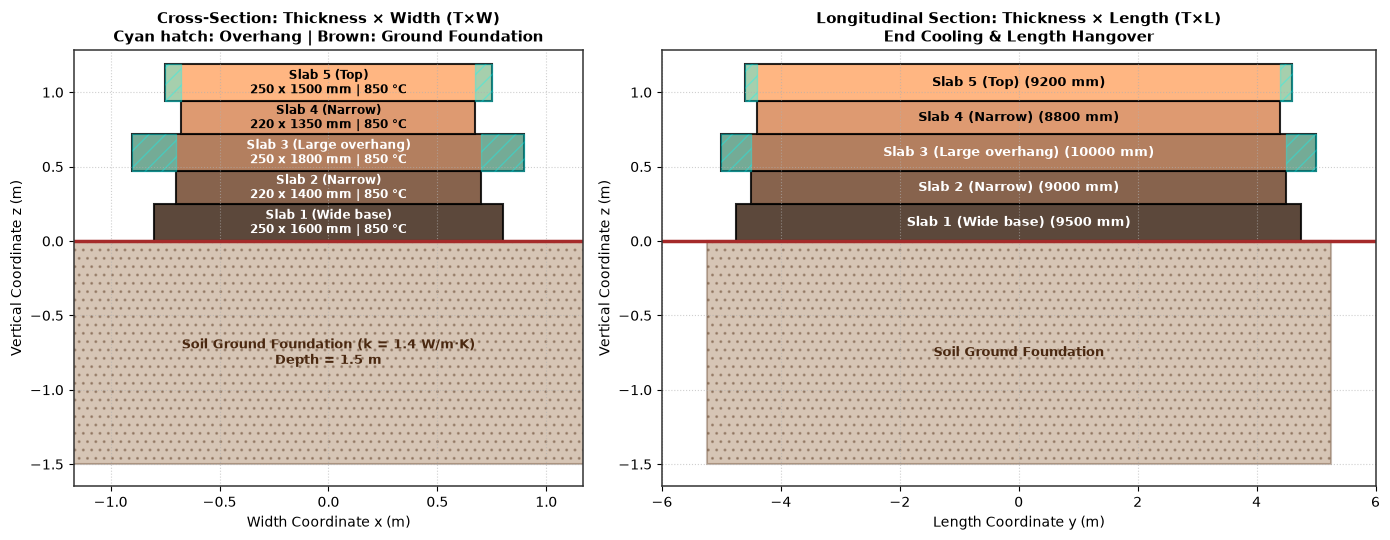

In [11]:
fig_geom = plot_pile_geometry(config)
plt.show()

## Material properties

The properties are carried as functions of temperature over the range a yard works in,
20 to 1000 °C:

- Conductivity $k(T)$ falls from 54 W/m·K at room temperature to 27.3 W/m·K in the austenite
  range (Eurocode 3, EN 1993-1-2).
- Apparent specific heat $c_p(T)$ carries the transformation latent heat, about 85 kJ/kg,
  centred at 735 °C, where the curve peaks and the code caps it at 5000 J/kg·K.
- Stored energy uses the analytical antiderivative $h(T) = \int_0^T c_p(t)\,dt$, so the energy
  balance across the peak is exact rather than trapezoidal.
- Air conductivity in the gap is evaluated at the interface temperature.


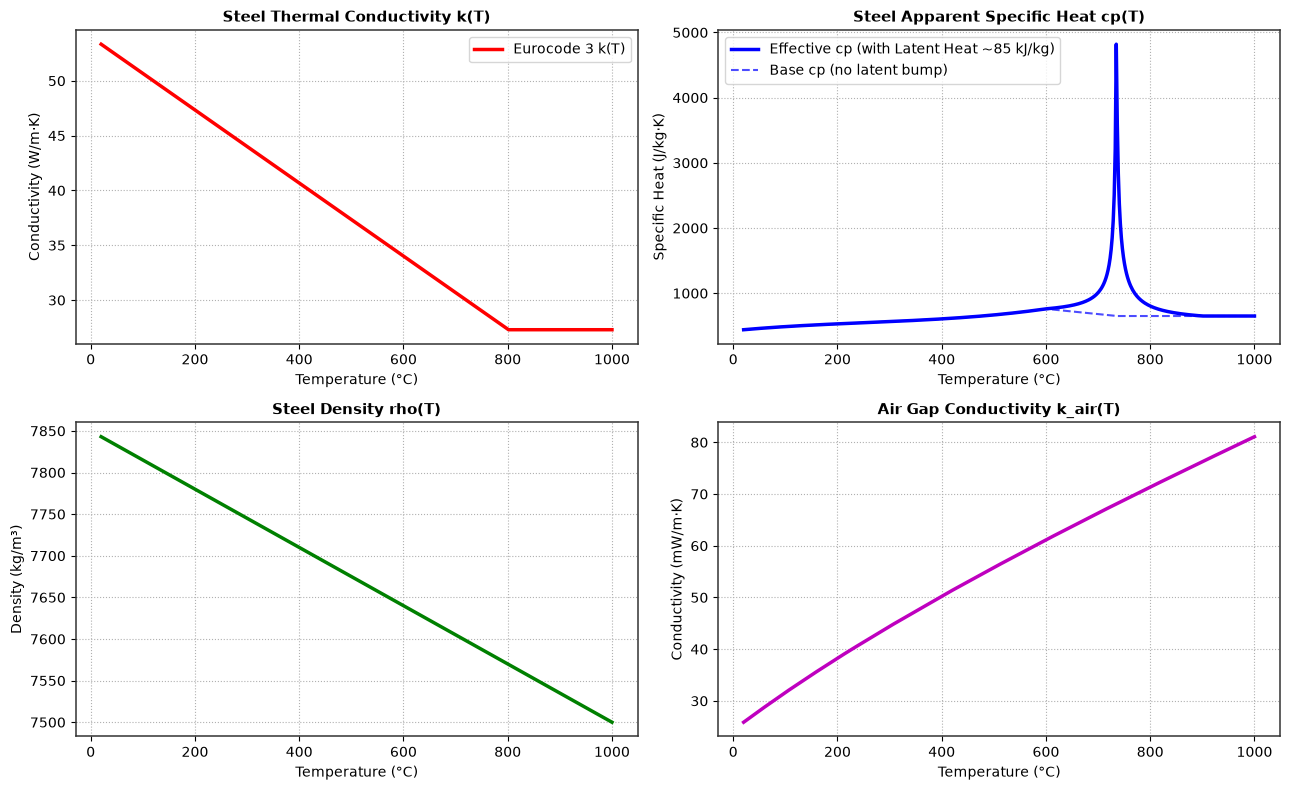

In [12]:
fig_props = plot_material_properties()
plt.show()

## The joint between two slabs

The interface conductance $h_c$ is built from five pieces:

1. Asperity contact at the peaks, governed by the hot hardness $H(T)$, the roughness $\sigma$
   and the contact pressure $P$.
2. Gas conduction in the valleys, over the roughness separation plus the waviness gap.
3. Radiation across the gap, $(T_1^4 - T_2^4)$, which dominates above about 500 °C.
4. The mill scale layer on each face, in series with everything above.
5. The buoyancy draft near open gap edges.

The pressure on a joint comes from the weight of the stack above it divided by the area that
actually overlaps, so a partial overlap is loaded harder than a joint of the same pile piled
tidily.


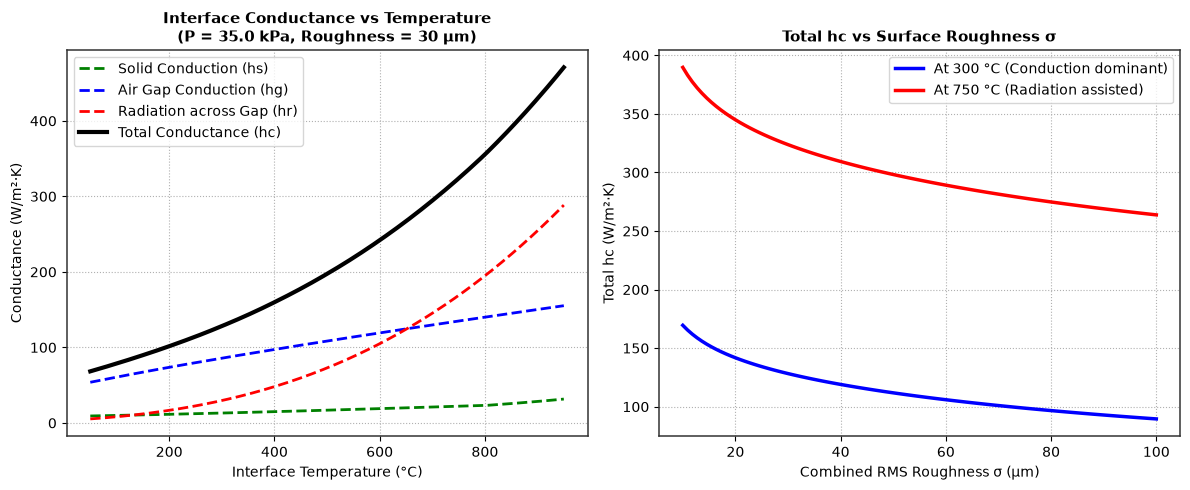

In [13]:
fig_hc = plot_interface_conductance(config.contact)
plt.show()

## Tier 1: the lumped baseline

A closed-form reference, computed before the full solve so the two can be compared:

- Biot number for each slab, $\text{Bi} = h_{\text{eff}} L_c / k$
- Lumped time constant, $\tau = \frac{m c_p}{\sum h A}$

It says how much of the holding time comes from the steel's own resistance to internal
conduction and how much from the stack insulating itself, which the full solve then quantifies.


In [14]:
df_tier1 = tier1_lumped_analysis(config)
display(df_tier1)

,Slab ID,Label,Thickness (mm),Width (mm),Length (mm),T0 (°C),Mass (t),Biot Number,Time Constant tau (h),Tier 1 RTP Est (h)
0,1,Slab 1 (Wide base),250,1600,9500,850,29.83,0.225,3.5,13.1
1,2,Slab 2 (Narrow),220,1400,9000,850,21.76,0.126,20.5,76.2
2,3,Slab 3 (Large overhang),250,1800,10000,850,35.33,0.130,9.7,35.9
3,4,Slab 4 (Narrow),220,1350,8800,850,20.52,0.126,19.8,73.6
4,5,Slab 5 (Top),250,1500,9200,850,27.08,0.143,5.6,20.6


## Grid and mesh

Two conforming finite volume meshes, one per cross section:

- The $T \times W$ section at mid length, which carries the width overhangs, the lateral
  interfaces and the soil layer.
- The $T \times L$ section at mid width, which carries the slab head and tail lengths, the
  longitudinal overhangs and the end faces.

Cells are refined through the thickness and near the overhang edges, where the gradients are
steepest.


In [15]:
# mesh for both sections
mesh_tw = generate_section_mesh(config, section="TW")
mesh_tl = generate_section_mesh(config, section="TL")

print(f"T×W Grid: Nx = {len(mesh_tw.dx)} cells, Nz = {len(mesh_tw.dz)} cells, Total Active Cells = {mesh_tw.num_active}")
print(f"T×L Grid: Nx = {len(mesh_tl.dx)} cells, Nz = {len(mesh_tl.dz)} cells, Total Active Cells = {mesh_tl.num_active}")

T×W Grid: Nx = 50 cells, Nz = 36 cells, Total Active Cells = 1140
T×L Grid: Nx = 66 cells, Nz = 36 cells, Total Active Cells = 1836


## Tier 2: the finite volume solve

The transient solve, implicit in time with a sparse matrix at every step:

- Face connectivities for the internal, interface and boundary faces are pre-compiled once, then
  reused at every time step.
- Stored energy is tracked through the analytical enthalpy, which is what keeps the energy
  balance inside half a per cent.
- The time step adapts to how fast the hottest cell is moving, not to the smallest cell in the
  mesh.
- Core, surface and mean temperatures, gradients and thermal stresses are recorded as the run
  proceeds.


In [16]:
print("Running Tier 2 FVM Simulation for T×W Cross-Section...")
t0 = time.time()
solver_tw = FvmSectionSolver(config, mesh_tw)
res_tw = solver_tw.solve(verbose=True)
t_tw = time.time() - t0
print(f"T×W solved in {t_tw:.2f} s ({len(res_tw.time_hours)} time steps). Cumulative Energy Balance Error = {res_tw.energy_balance_error_pct:.2f}%\n")

print("Running Tier 2 FVM Simulation for T×L Longitudinal Section...")
t0 = time.time()
solver_tl = FvmSectionSolver(config, mesh_tl)
res_tl = solver_tl.solve(verbose=False)
t_tl = time.time() - t0
print(f"T×L solved in {t_tl:.2f} s ({len(res_tl.time_hours)} time steps). Cumulative Energy Balance Error = {res_tl.energy_balance_error_pct:.2f}%")

Running Tier 2 FVM Simulation for T×W Cross-Section...


All slabs reached RTP target (50.0 °C) at t = 118.18 h.
T×W solved in 7.26 s (805 time steps). Cumulative Energy Balance Error = 0.92%

Running Tier 2 FVM Simulation for T×L Longitudinal Section...


T×L solved in 7.79 s (593 time steps). Cumulative Energy Balance Error = 0.15%


## Contours of the temperature field

Isotherms across the stack at the recorded times:

- The exposed overhang wings and the top slab lose heat fastest.
- The cores of the middle slabs hold their temperature long after the surface has dropped.
- Heat moves down into the soil layer under the bottom slab.


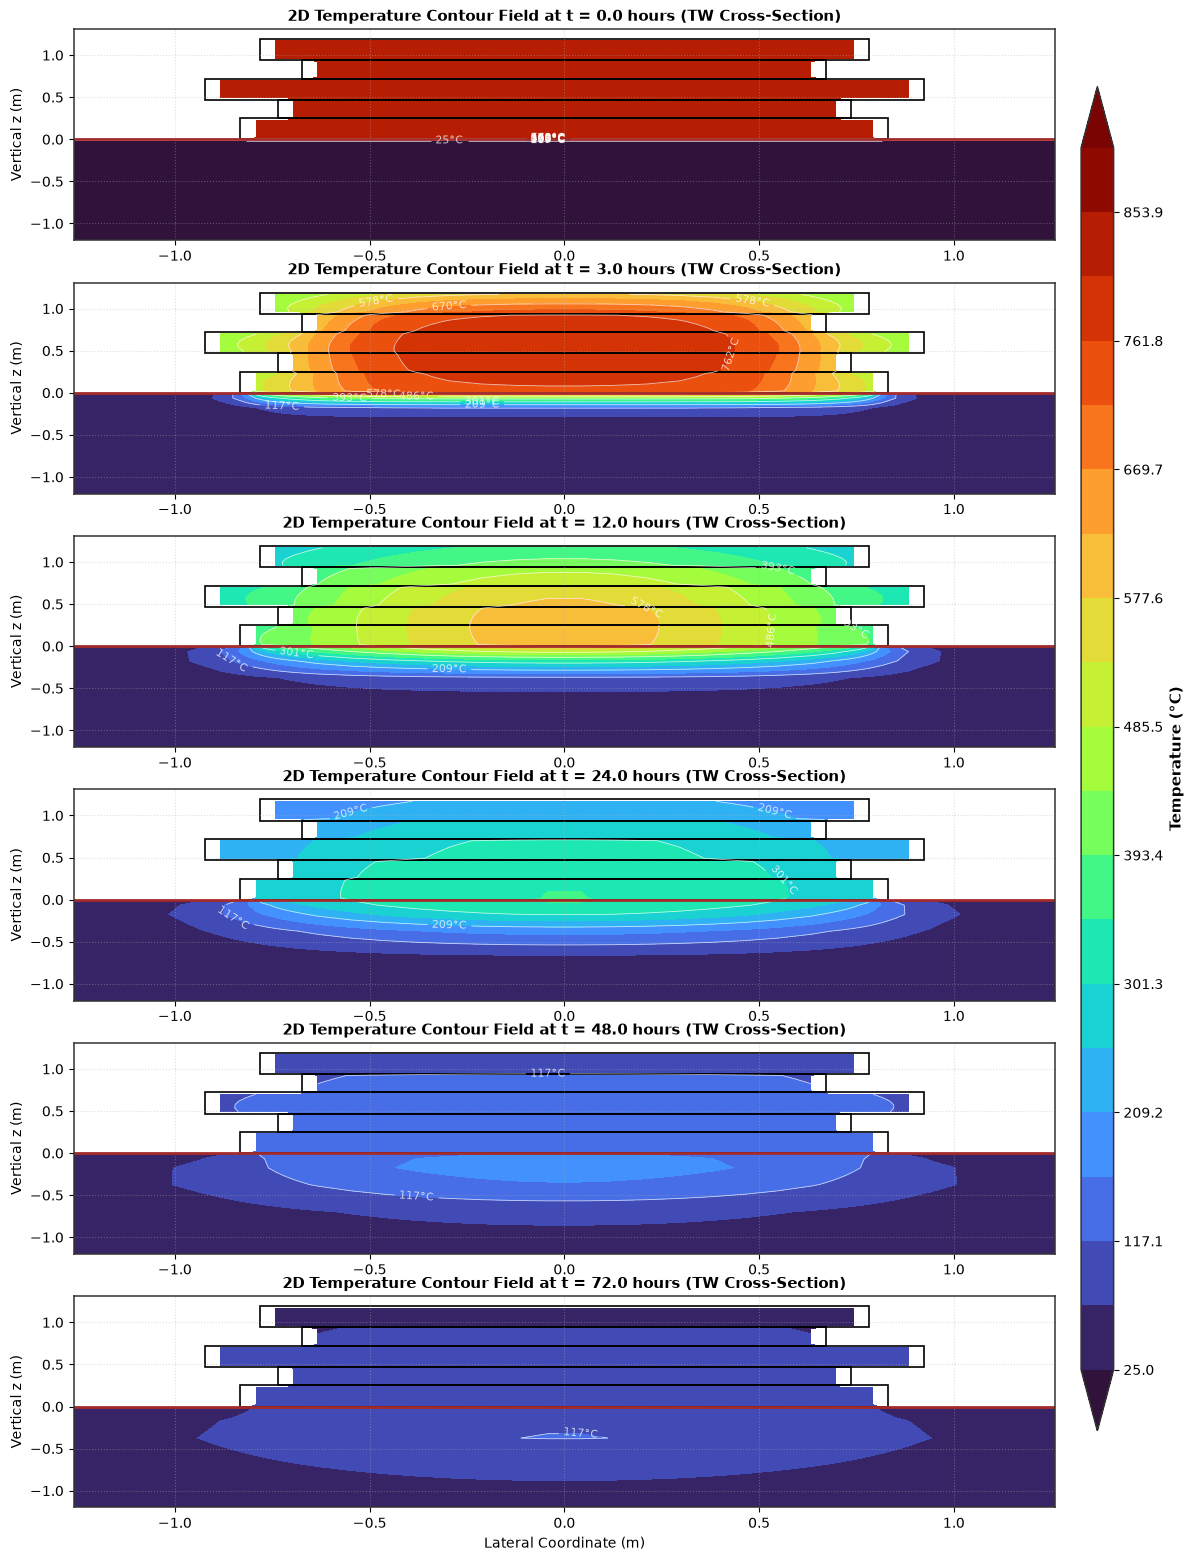

In [17]:
# contours at the recorded times
fig_contour = plot_contour_temperature_maps(res_tw, selected_times=[0.0, 3.0, 12.0, 24.0, 48.0, 72.0])
plt.show()

## Temperature evolution, interactive

The slider moves through the cooling run from the moment of stacking ($t = 0$) to the release
temperature ($t = t_{\text{RTP}}$).


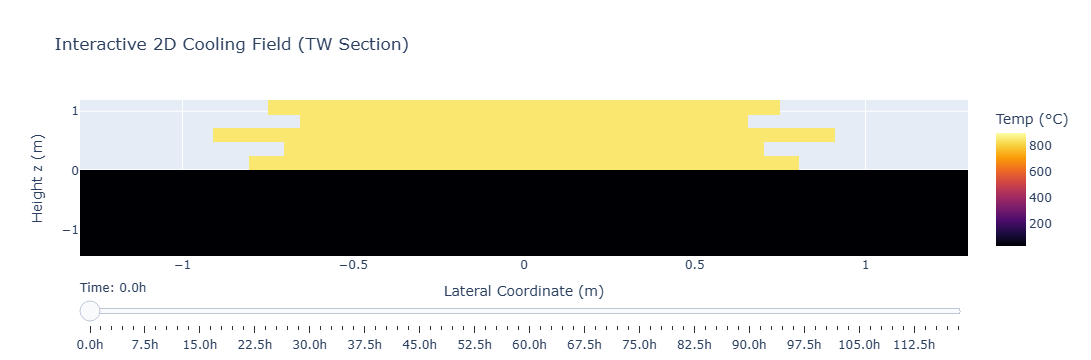

In [18]:
# interactive slice through the run
fig_slider = create_interactive_plotly_heatmap(res_tw)
display(fig_slider)

## Cooling histories

Four panels from the same run:

1. Core (solid) and surface (dotted) temperature against time, with the release threshold.
2. The through-thickness difference $\Delta T$ between core and surface.
3. Cooling rate in °C per hour for each slab.
4. Where the heat went: cumulative loss rate in kW split between the top surface, the vertical
   sides, the overhang wings and the ground.


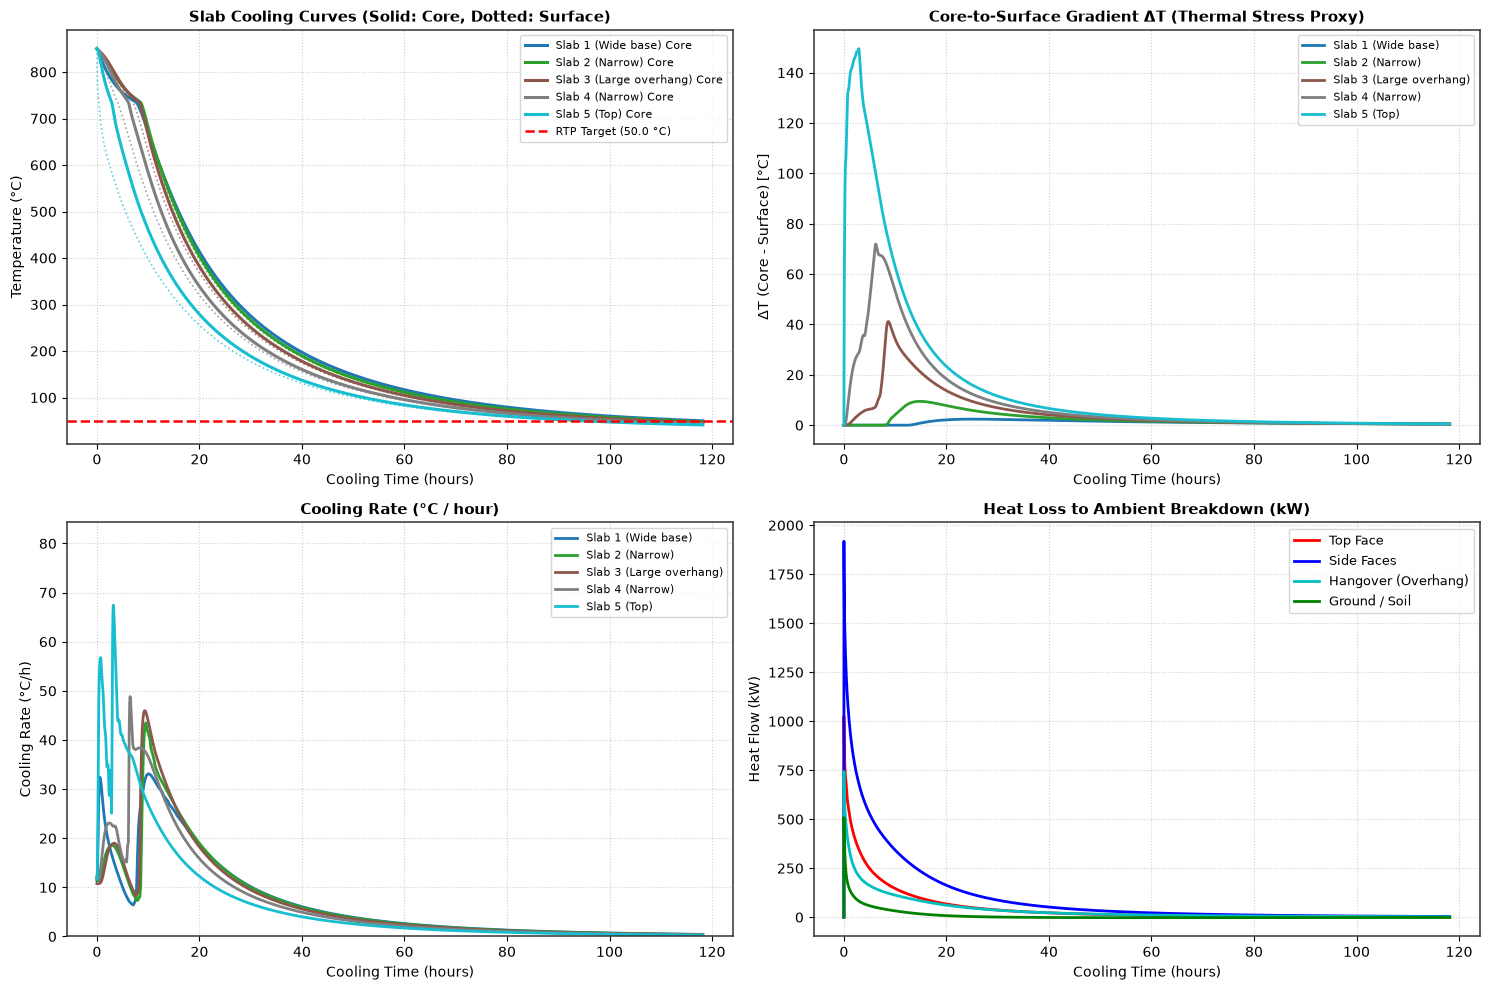

In [19]:
fig_hist = plot_temperature_histories(res_tw, config)
plt.show()

## Gradients, stress and cracking risk

Non-uniform cooling means differential contraction, which puts the surface into tension:

- The through-thickness difference $\Delta T = T_{\text{core}} - T_{\text{surface}}$, largest
  early, when the surface is quenched while the core is still near 850 °C.
- The vertical gradient $|\partial T / \partial z|$ in °C/mm, the steepness of conduction
  through the thickness.

$$\sigma_{\text{surf}} \approx \frac{E(T)\,\alpha(T)}{1 - \nu}\,\frac{2}{3}\,\Delta T$$

$$\text{stress ratio} = \frac{\sigma_{\text{surf}}}{R_{eH}(T)}$$

Above about 0.8 the notebook flags a real risk of surface micro-cracking or permanent warping.


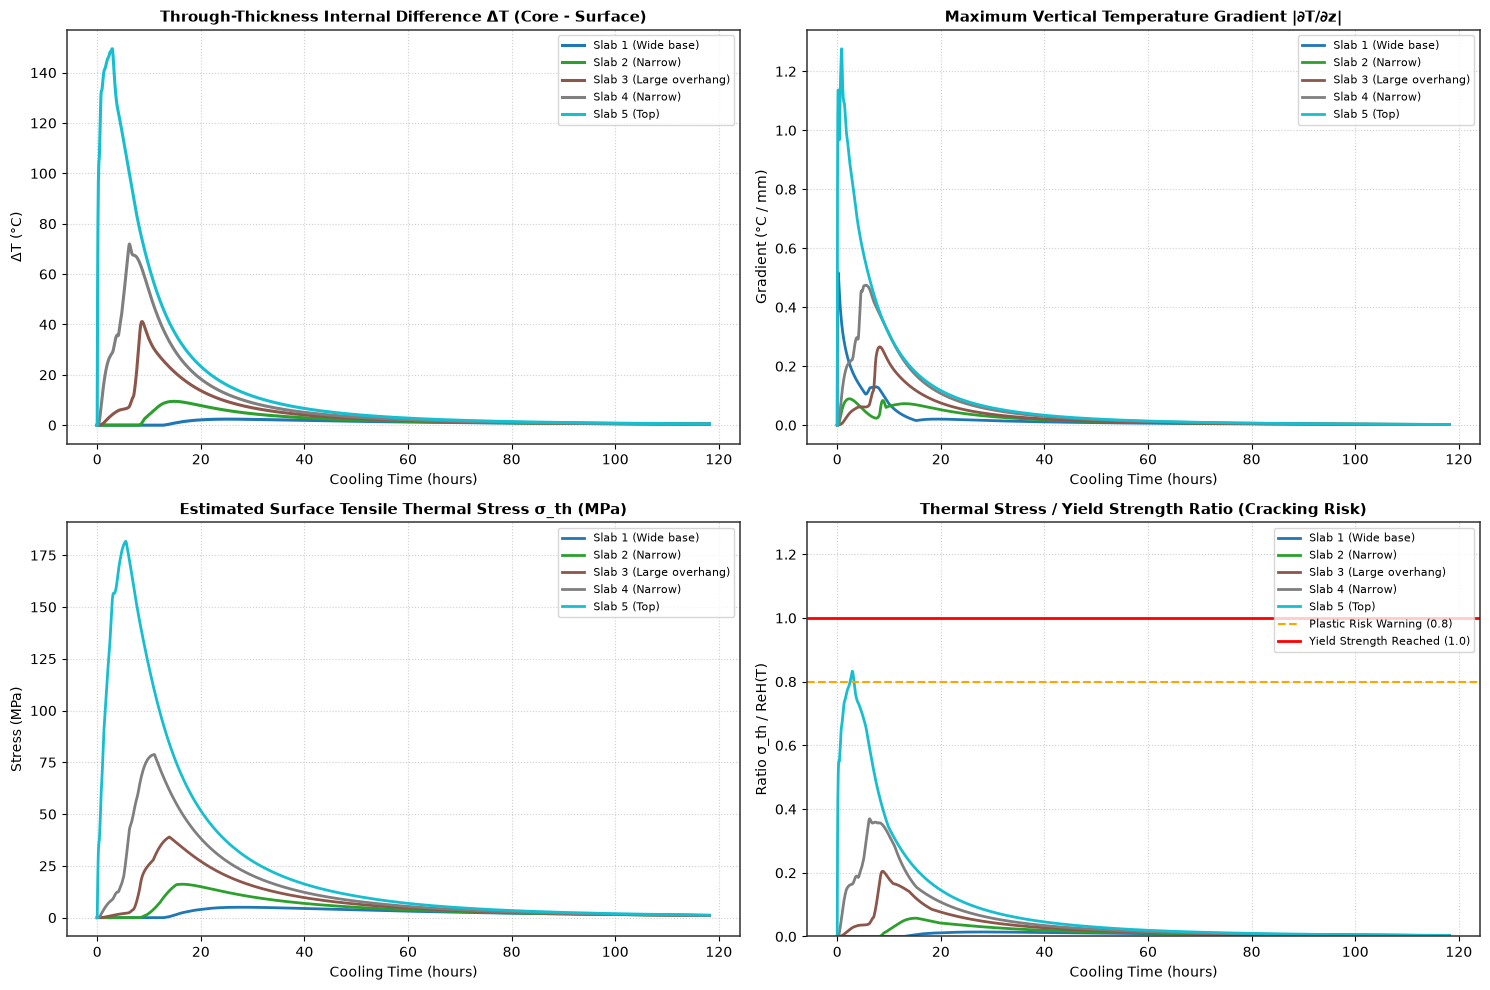

In [20]:
fig_grad = plot_thermal_gradients_and_stress(res_tw, config)
plt.show()

## What the overhang does

An exposed wing loses heat from its top, its underside and its end face at once, so it cools
faster than the root of the same slab and sets up a lateral gradient across the width.


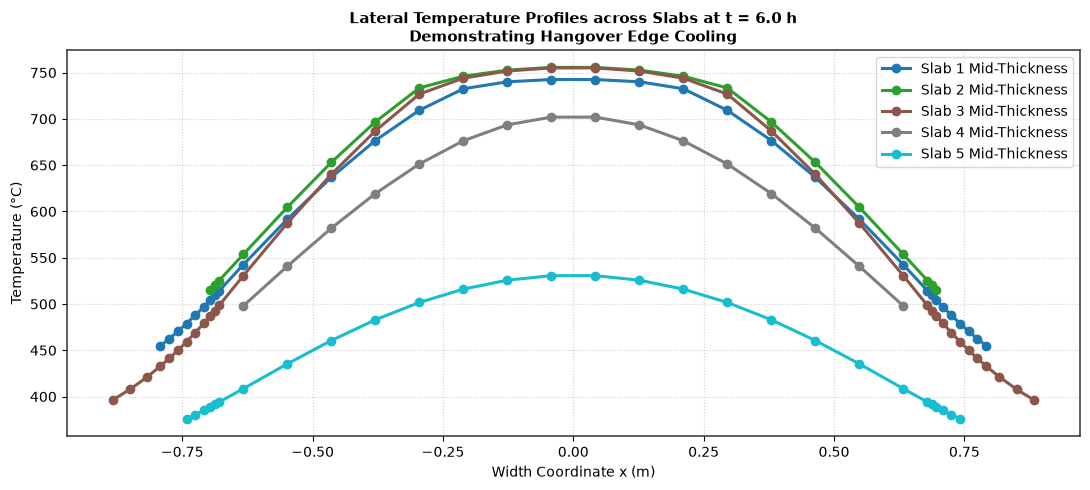

In [21]:
fig_hang = plot_hangover_profile(res_tw, time_h=6.0)
plt.show()

## Width section against length section

The two sections side by side. The length section shows what the end faces are worth and how the
longitudinal overhangs behave; the width section shows the lateral cooling and the soil contact.
The pile is clear when the slower of the two says it is.


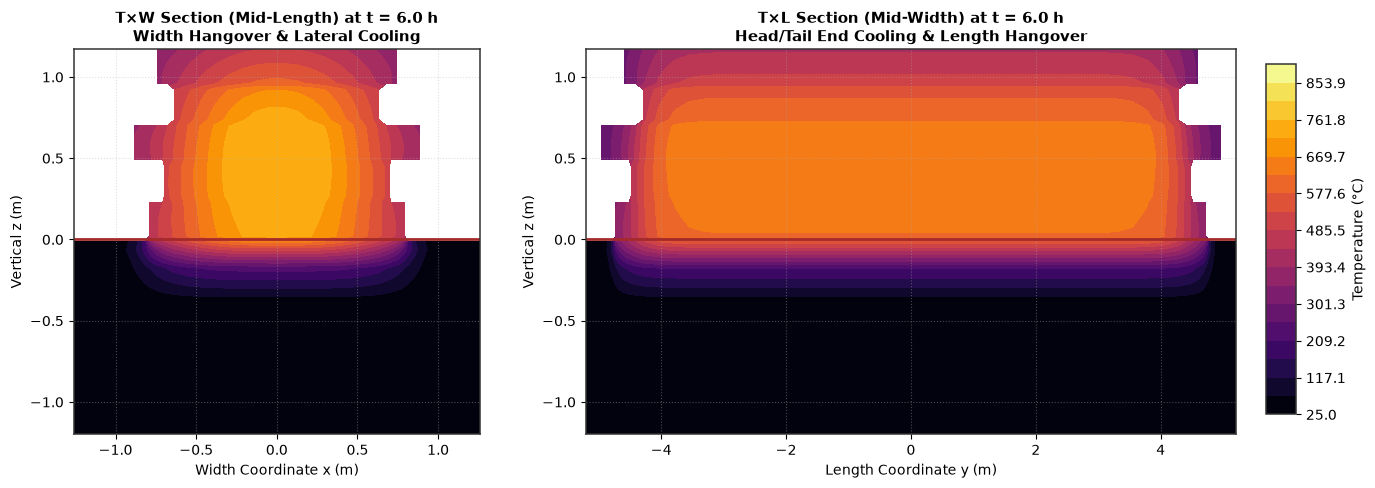

In [22]:
fig_2d_comp = plot_2d_evolution_comparison(res_tw, res_tl, time_h=6.0)
plt.show()

## Time to the release target, by slab

Time for each slab to reach the release temperature
($T_{\text{RTP}} = 50\,^\circ\text{C}$), on the core, mean and surface criteria. The slab that
reaches it last is the one that sets the pile's dispatch date.


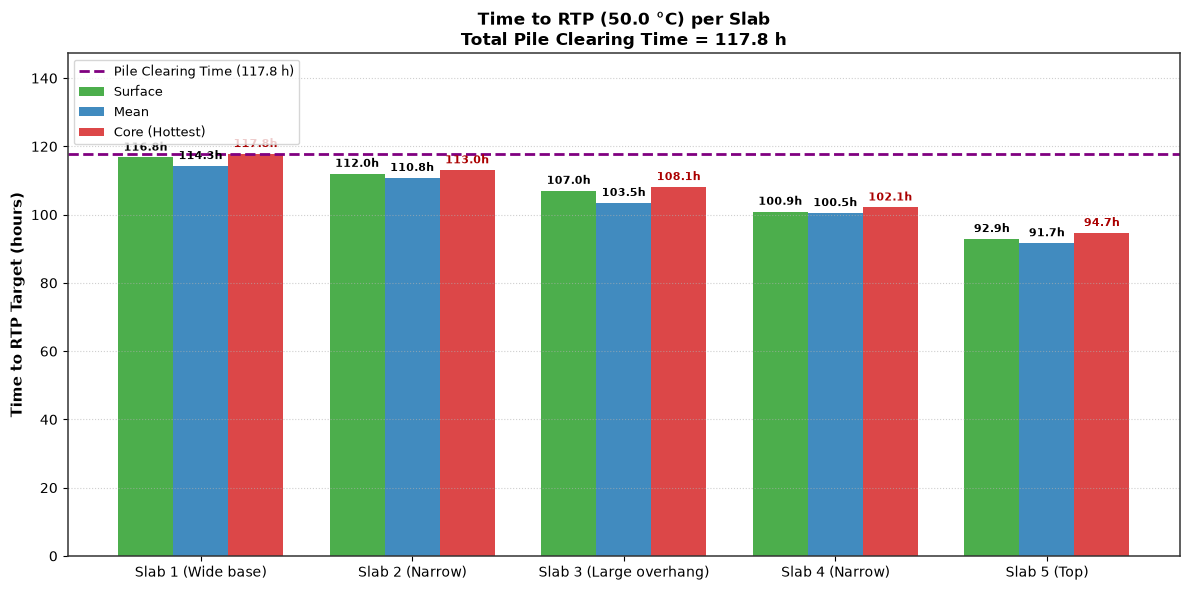

=== TOTAL PILE CLEARING TIME: 117.8 hours ===


,Slab,Thickness (mm),Width (mm),T0 (°C),Surface RTP (h),Mean RTP (h),Core RTP (h)
0,Slab 1 (Wide base),250,1600,850,116.8,114.3,117.8
1,Slab 2 (Narrow),220,1400,850,112.0,110.8,113.0
2,Slab 3 (Large overhang),250,1800,850,107.0,103.5,108.1
3,Slab 4 (Narrow),220,1350,850,100.9,100.5,102.1
4,Slab 5 (Top),250,1500,850,92.9,91.7,94.7


In [23]:
fig_rtp = plot_time_to_rtp_bars(res_tw, config)
plt.show()

# release times by slab
df_rtp = pd.DataFrame([{
    "Slab": s.label,
    "Thickness (mm)": s.thickness,
    "Width (mm)": s.width,
    "T0 (°C)": s.initial_temp,
    "Surface RTP (h)": round(res_tw.t_rtp_surf[s.id], 1) if not np.isnan(res_tw.t_rtp_surf[s.id]) else "> sim time",
    "Mean RTP (h)": round(res_tw.t_rtp_mean[s.id], 1) if not np.isnan(res_tw.t_rtp_mean[s.id]) else "> sim time",
    "Core RTP (h)": round(res_tw.t_rtp_core[s.id], 1) if not np.isnan(res_tw.t_rtp_core[s.id]) else "> sim time",
} for s in config.slabs])

pile_rtp_str = f"{res_tw.pile_rtp_time:.1f} hours" if not np.isnan(res_tw.pile_rtp_time) else f"> {res_tw.time_hours[-1]:.1f} hours (In-Progress)"
print(f"=== TOTAL PILE CLEARING TIME: {pile_rtp_str} ===")
display(df_rtp)

## Tier 1 against Tier 2

The lumped baseline beside the full solve, which shows how much the stack's own insulation and
the internal conduction resistance add to the holding time.


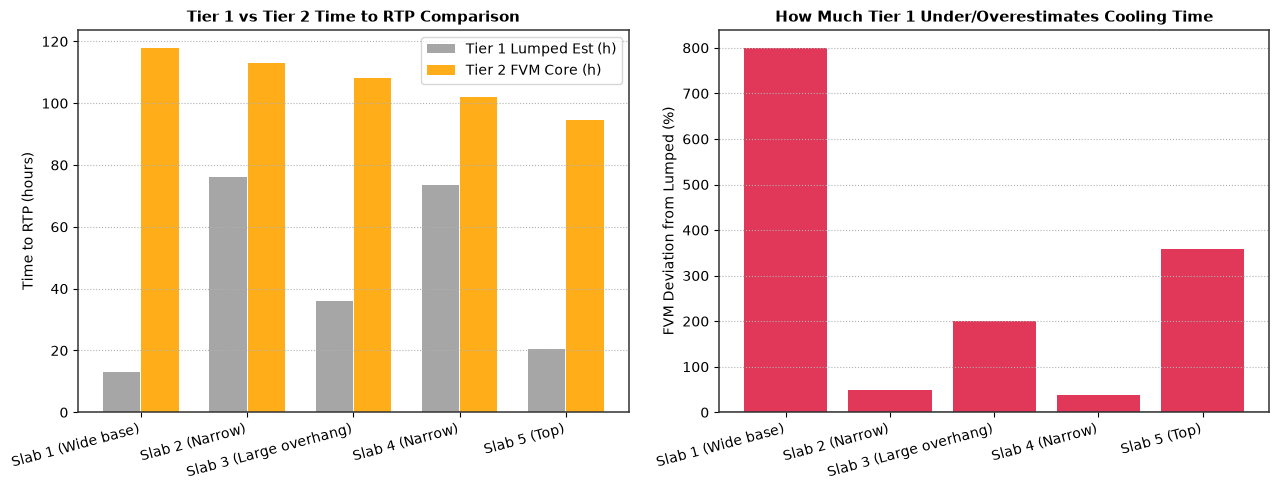

In [24]:
fig_t1_t2 = plot_tier1_vs_tier2(res_tw, df_tier1)
plt.show()

## Uncertainty envelope

Yard parameters vary, and the planner rarely knows them at the time of the decision:

- Wind from 0.3 to 2.5 m/s
- Waviness gap from 0.2 to 0.8 mm
- Mill scale emissivity from 0.76 to 0.86
- Soil conductivity from 1.1 to 1.8 W/m·K
- Ambient temperature within 5 °C of nominal

The samples are drawn over those ranges and reported as:

- P10, the fastest plausible release, for the optimistic plan.
- P50, the median, which is the number to schedule against.
- P90, the release that survives the worst plausible combination.
- A tornado ranking, which says which of the variables above is doing the damage.


Running Monte Carlo Uncertainty Quantification (20 Latin Hypercube samples)...


UQ ensemble completed in 105.3 s.

=== PILE CLEARING TIME CONFIDENCE ENVELOPE ===
  P10 (fastest)      : 103.5 hours
  P50 (median)       : 114.5 hours
  P90 (conservative) : 126.3 hours



,Slab,P10 RTP (h),P50 RTP (h),P90 RTP (h)
0,Slab 1 (Wide base),103.5,114.5,126.3
1,Slab 2 (Narrow),99.4,109.9,120.7
2,Slab 3 (Large overhang),95.1,105.1,114.6
3,Slab 4 (Narrow),90.1,99.4,107.2
4,Slab 5 (Top),82.9,92.0,97.4


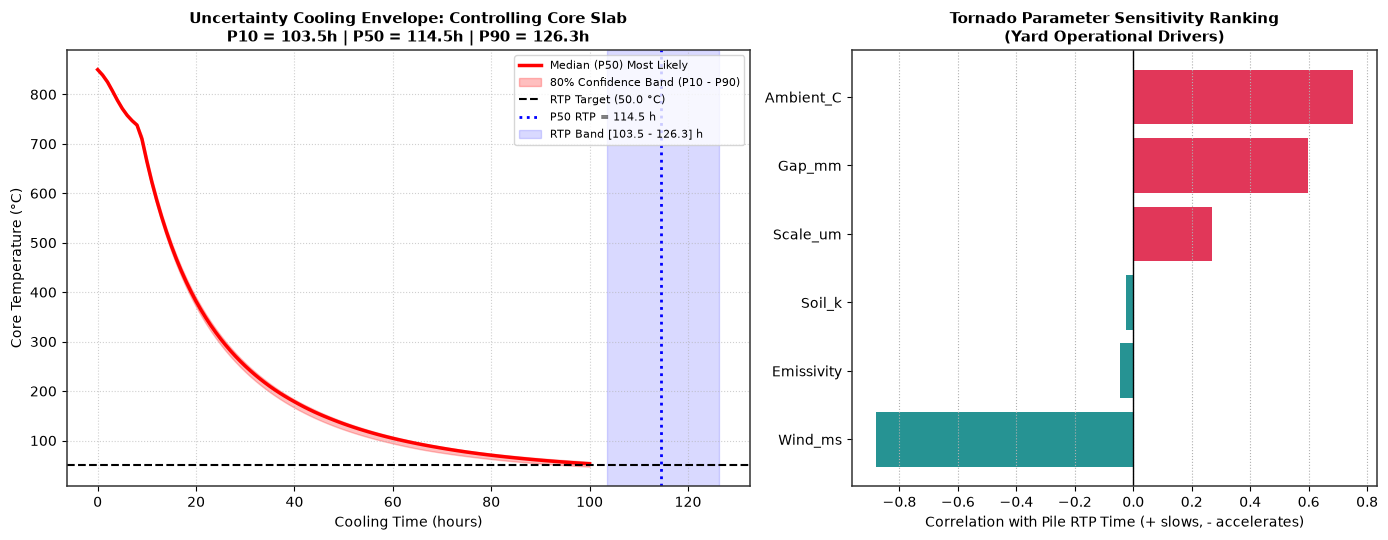

In [25]:
print("Running Monte Carlo Uncertainty Quantification (20 Latin Hypercube samples)...")
t0 = time.time()
uq_results = run_uncertainty_analysis(config, n_samples=20, seed=42)
t_uq = time.time() - t0
print(f"UQ ensemble completed in {t_uq:.1f} s.\n")

print(f"=== PILE CLEARING TIME CONFIDENCE ENVELOPE ===")
print(f"  P10 (fastest)      : {uq_results.pile_rtp_p10:.1f} hours")
print(f"  P50 (median)       : {uq_results.pile_rtp_p50:.1f} hours")
print(f"  P90 (conservative) : {uq_results.pile_rtp_p90:.1f} hours\n")

display(uq_results.slab_rtp_quantiles)

# envelope and sensitivity
fig_uq = plot_uncertainty_bands(uq_results, config)
plt.show()

## Verification

Three checks run before the results are reported:

1. The solver against the exact infinite series solution for a plate cooling with convective
   faces.
2. The soil model against the complementary error function solution for semi-infinite
   conduction.
3. An energy balance: the enthalpy released, $\Delta H = \sum M_p (h_0 - h_t)$, against the
   integral of the boundary losses, $\int Q_{\text{bnd}}\,dt$. The target is half a per cent.


Analytical Fourier Series: Max deviation = 2.01 °C, RMS = 1.51 °C over 850 -> 50 °C range.
Energy Conservation Balance: Cumulative Error = 0.0000% (Target < 0.5%).
Full Pile Simulation Energy Error = 0.915%.


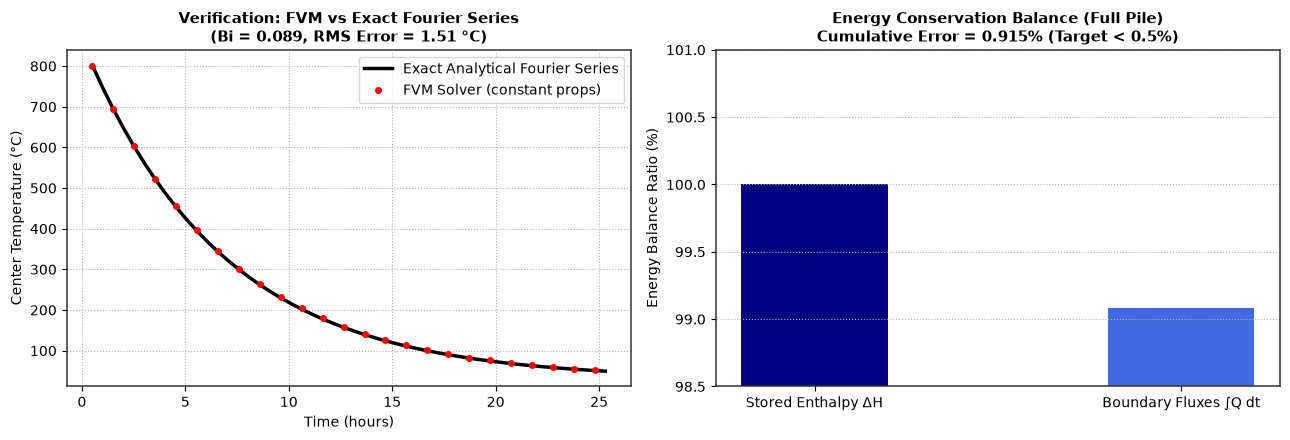

In [26]:
# verification suite
v_results = run_verification_suite()

print(f"Analytical Fourier Series: Max deviation = {v_results['fourier_max_dev_C']:.2f} °C, RMS = {v_results['fourier_rms_dev_C']:.2f} °C over 850 -> 50 °C range.")
print(f"Energy Conservation Balance: Cumulative Error = {v_results['energy_error_pct']:.4f}% (Target < 0.5%).")
print(f"Full Pile Simulation Energy Error = {res_tw.energy_balance_error_pct:.3f}%.")

# verification against the series solution
th = 0.25
k_const, rho_const, cp_const, h_const = 35.0, 7850.0, 600.0, 25.0
alpha_const = k_const / (rho_const * cp_const)
T0_val, T_inf_val = 850.0, 30.0

cfg_val = SimulationConfig(slabs=[Slab(id=1, thickness=250, width=1500, length=9000, initial_temp=T0_val, label="Val Slab")])
cfg_val.env.t_ambient = T_inf_val
cfg_val.env.wind_speed = 0.0
cfg_val.env.h_ground = h_const
cfg_val.env.h_override = h_const
cfg_val.contact.emissivity = 0.0
cfg_val.soil.enabled = False
cfg_val.const_k = k_const
cfg_val.const_cp = cp_const
cfg_val.const_rho = rho_const
cfg_val.adiabatic_sides = True
cfg_val.depth_correction = False
cfg_val.t_rtp = 50.0

mesh_val = generate_section_mesh(cfg_val, section="TW")
res_val = FvmSectionSolver(cfg_val, mesh_val).solve(max_hours=40.0)

t_eval_h = np.linspace(0.5, res_val.time_hours[-1] - 0.2, 50)
T_fourier = analytical_fourier_slab(th, T0_val, T_inf_val, h_const, k_const, alpha_const, t_eval_h * 3600.0)
T_fvm = np.interp(t_eval_h, res_val.time_hours, res_val.core_temps[:, 0])

fig_val, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
ax1.plot(t_eval_h, T_fourier, 'k-', linewidth=2.5, label='Exact Analytical Fourier Series')
ax1.plot(t_eval_h, T_fvm, 'ro', markersize=4, markevery=2, label='FVM Solver (constant props)')
ax1.set_title(f"Verification: FVM vs Exact Fourier Series\n(Bi = {h_const*(th/2)/k_const:.3f}, RMS Error = {v_results['fourier_rms_dev_C']:.2f} °C)", fontsize=11, fontweight='bold')
ax1.set_xlabel("Time (hours)")
ax1.set_ylabel("Center Temperature (°C)")
ax1.grid(True, linestyle=':')
ax1.legend()

# energy balance
ax2.bar(['Stored Enthalpy ΔH', 'Boundary Fluxes ∫Q dt'], [100.0, 100.0 - res_tw.energy_balance_error_pct], color=['navy', 'royalblue'], width=0.4)
ax2.set_ylabel("Energy Balance Ratio (%)")
ax2.set_ylim(98.5, 101.0)
ax2.set_title(f"Energy Conservation Balance (Full Pile)\nCumulative Error = {res_tw.energy_balance_error_pct:.3f}% (Target < 0.5%)", fontsize=11, fontweight='bold')
ax2.grid(True, axis='y', linestyle=':')

plt.tight_layout()
plt.show()

## What the run says

1. The middle slabs are insulated by their neighbours and hold above 200 °C long after the outer
   slabs are cold. That is what sets the pile's release date.
2. Heat going into the soil builds a warm patch under the pile, which slows the bottom slab
   compared with a pile on cold ground.
3. The overhang wings cool faster than the covered areas of the same slab, so they carry the
   steepest lateral gradients.
4. Surface stress peaks early, while the core is still hot and the surface has just been
   quenched.
5. Depiling the cold top and bottom slabs first lets the insulated core cool faster, which is
   the lever a yard can actually pull.


In [27]:
# write the cooling curves
export_data = {"Time_Hours": res_tw.time_hours}
for i, s in enumerate(config.slabs):
    export_data[f"Slab_{s.id}_Core_T_C"] = res_tw.core_temps[:, i]
    export_data[f"Slab_{s.id}_Surf_T_C"] = res_tw.surf_temps[:, i]
    export_data[f"Slab_{s.id}_DeltaT_C"] = res_tw.delta_T_core_surf[:, i]
    export_data[f"Slab_{s.id}_Stress_MPa"] = res_tw.thermal_stress_surface[:, i]

df_export = pd.DataFrame(export_data)
df_export.to_csv("slab_pile_cooling_history.csv", index=False)
print(f"Cooling history successfully exported to 'slab_pile_cooling_history.csv' ({len(df_export)} rows, {len(df_export.columns)} columns).")
print("Refined simulation complete. All physical models, soil foundation, thermal stresses, and UQ envelopes ready.")

Cooling history successfully exported to 'slab_pile_cooling_history.csv' (805 rows, 21 columns).
Refined simulation complete. All physical models, soil foundation, thermal stresses, and UQ envelopes ready.
